In [1]:

# Speed-Related Factors and Occupant Injury Severity in U.S. Fatal Crashes: A 2023 FARS Analysis

## 1. Research Purpose

This study will examine the association between speed-related factors, roadway and lighting conditions, occupant characteristics, and injury severity among occupants involved in fatal motor-vehicle crashes in the United States in 2023.

## 2. Research Questions

1. Which crash, roadway, and occupant characteristics are associated with severe or fatal injury outcomes among occupants involved in 2023 U.S. fatal crashes?
2. Does the association between speed-related factors and injury severity vary across lighting conditions?
3. How robust are the findings to missing data, crash-level clustering, and alternative model specifications?

## 3. Data Source

Fatality Analysis Reporting System (FARS), National Highway Traffic Safety Administration (NHTSA), 2023.

## 4. Important Research Limitation

FARS records fatal motor-vehicle crashes. Therefore, this study examines injury severity among occupants involved in fatal crashes; it does not estimate injury risk across all road crashes. The results will be interpreted as associations, not causal effects.

## 5. Workflow

1. Locate and load the 2023 FARS data.
2. Inspect the datasets and official variable definitions.
3. Clean the data and examine missing values.
4. Define the study population and injury-severity outcome.
5. Conduct exploratory data analysis.
6. Fit and evaluate appropriate statistical models.
7. Perform robustness checks and interpret the findings.
8. Write the research report and document the analysis.


SyntaxError: invalid syntax (1756055432.py, line 5)


# Speed-Related Factors and Occupant Injury Severity in U.S. Fatal Crashes: A 2023 FARS Analysis

## 1. Research Purpose

This study will examine the association between speed-related factors, roadway and lighting conditions, occupant characteristics, and injury severity among occupants involved in fatal motor-vehicle crashes in the United States in 2023.

## 2. Research Questions

1. Which crash, roadway, and occupant characteristics are associated with severe or fatal injury outcomes among occupants involved in 2023 U.S. fatal crashes?
2. Does the association between speed-related factors and injury severity vary across lighting conditions?
3. How robust are the findings to missing data, crash-level clustering, and alternative model specifications?

## 3. Data Source

Fatality Analysis Reporting System (FARS), National Highway Traffic Safety Administration (NHTSA), 2023.

## 4. Important Research Limitation

FARS records fatal motor-vehicle crashes. Therefore, this study examines injury severity among occupants involved in fatal crashes; it does not estimate injury risk across all road crashes. The results will be interpreted as associations, not causal effects.

## 5. Workflow

1. Locate and load the 2023 FARS data.
2. Inspect the datasets and official variable definitions.
3. Clean the data and examine missing values.
4. Define the study population and injury-severity outcome.
5. Conduct exploratory data analysis.
6. Fit and evaluate appropriate statistical models.
7. Perform robustness checks and interpret the findings.
8. Write the research report and document the analysis.


In [2]:

print("FARS 2023 Traffic Safety Research")
print("Python is working correctly!")


FARS 2023 Traffic Safety Research
Python is working correctly!


In [5]:

import os

print("Checking Google Drive and common folders...")

print("\nFiles in /content:")
print(os.listdir("/content"))


Checking Google Drive and common folders...

Files in /content:
['.config', 'sample_data']


In [6]:

from google.colab import files

uploaded = files.upload()


Saving FARS2023NationalCSV.zip to FARS2023NationalCSV.zip


In [7]:

import os
import glob
import zipfile
import pandas as pd

# 1. Find the uploaded ZIP file
zip_files = glob.glob("/content/*.zip")

if not zip_files:
    raise FileNotFoundError(
        "ZIP file not found in /content. Please upload FARS2023NationalCSV.zip again."
    )

zip_path = next(
    (f for f in zip_files if "fars2023" in os.path.basename(f).lower()),
    zip_files[0]
)

# 2. Extract the ZIP file
extract_dir = "/content/fars2023_data"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("ZIP file extracted:", os.path.basename(zip_path))

# 3. Locate the three main CSV files
csv_files = glob.glob(
    os.path.join(extract_dir, "**", "*.csv"),
    recursive=True
)

csv_lookup = {
    os.path.basename(path).lower(): path
    for path in csv_files
}

required_files = ["accident.csv", "person.csv", "vehicle.csv"]
missing_files = [f for f in required_files if f not in csv_lookup]

if missing_files:
    print("Required files not found:", missing_files)
    print("CSV files available:", list(csv_lookup.keys())[:30])
else:
    # 4. Load the datasets
    accident = pd.read_csv(csv_lookup["accident.csv"], low_memory=False)
    person = pd.read_csv(csv_lookup["person.csv"], low_memory=False)
    vehicle = pd.read_csv(csv_lookup["vehicle.csv"], low_memory=False)

    # 5. Summarize dataset dimensions
    print("\nDATASET SIZES")
    print("Accident:", accident.shape)
    print("Person:", person.shape)
    print("Vehicle:", vehicle.shape)

    # 6. Inspect important information
    for name, df in [
        ("ACCIDENT", accident),
        ("PERSON", person),
        ("VEHICLE", vehicle)
    ]:
        print(f"\n{'=' * 50}")
        print(name)
        print("=" * 50)
        print("\nColumn names:")
        print(df.columns.tolist())
        print("\nFirst 5 rows:")
        display(df.head())

    print("\nAll three datasets loaded successfully.")


ZIP file extracted: FARS2023NationalCSV.zip

DATASET SIZES
Accident: (37769, 80)
Person: (92768, 126)
Vehicle: (58508, 203)

ACCIDENT

Column names:
['STATE', 'STATENAME', 'ST_CASE', 'PEDS', 'PERNOTMVIT', 'VE_TOTAL', 'VE_FORMS', 'PVH_INVL', 'PERSONS', 'PERMVIT', 'COUNTY', 'COUNTYNAME', 'CITY', 'CITYNAME', 'MONTH', 'MONTHNAME', 'DAY', 'DAYNAME', 'DAY_WEEK', 'DAY_WEEKNAME', 'YEAR', 'HOUR', 'HOURNAME', 'MINUTE', 'MINUTENAME', 'TWAY_ID', 'TWAY_ID2', 'ROUTE', 'ROUTENAME', 'RUR_URB', 'RUR_URBNAME', 'FUNC_SYS', 'FUNC_SYSNAME', 'RD_OWNER', 'RD_OWNERNAME', 'NHS', 'NHSNAME', 'SP_JUR', 'SP_JURNAME', 'MILEPT', 'MILEPTNAME', 'LATITUDE', 'LATITUDENAME', 'LONGITUD', 'LONGITUDNAME', 'HARM_EV', 'HARM_EVNAME', 'MAN_COLL', 'MAN_COLLNAME', 'RELJCT1', 'RELJCT1NAME', 'RELJCT2', 'RELJCT2NAME', 'TYP_INT', 'TYP_INTNAME', 'REL_ROAD', 'REL_ROADNAME', 'WRK_ZONE', 'WRK_ZONENAME', 'LGT_COND', 'LGT_CONDNAME', 'WEATHER', 'WEATHERNAME', 'SCH_BUS', 'SCH_BUSNAME', 'RAIL', 'RAILNAME', 'NOT_HOUR', 'NOT_HOURNAME', 'NOT_MIN

,STATE,STATENAME,ST_CASE,PEDS,PERNOTMVIT,VE_TOTAL,VE_FORMS,PVH_INVL,PERSONS,PERMVIT,...,NOT_MINNAME,ARR_HOUR,ARR_HOURNAME,ARR_MIN,ARR_MINNAME,HOSP_HR,HOSP_HRNAME,HOSP_MN,HOSP_MNNAME,FATALS
0,1,Alabama,10001,0,0,1,1,0,1,1,...,20,22,10:00pm-10:59pm,45,45,88,Not Applicable (Not Transported),88,Not Applicable (Not Transported),1
1,1,Alabama,10002,0,0,1,1,0,1,1,...,8,2,2:00am-2:59am,23,23,88,Not Applicable (Not Transported),88,Not Applicable (Not Transported),1
2,1,Alabama,10003,0,0,1,1,0,1,1,...,48,23,11:00pm-11:59pm,8,8,88,Not Applicable (Not Transported),88,Not Applicable (Not Transported),1
3,1,Alabama,10004,0,0,1,1,0,3,3,...,0,19,7:00pm-7:59pm,44,44,99,Unknown,99,Unknown EMS Hospital Arrival Time,1
4,1,Alabama,10005,0,0,1,1,0,4,4,...,53,15,3:00pm-3:59pm,8,8,99,Unknown,99,Unknown EMS Hospital Arrival Time,1



PERSON

Column names:
['STATE', 'STATENAME', 'ST_CASE', 'VEH_NO', 'PER_NO', 'VE_FORMS', 'COUNTY', 'MONTH', 'MONTHNAME', 'DAY', 'DAYNAME', 'HOUR', 'HOURNAME', 'MINUTE', 'MINUTENAME', 'HARM_EV', 'HARM_EVNAME', 'MAN_COLL', 'MAN_COLLNAME', 'SCH_BUS', 'SCH_BUSNAME', 'RUR_URB', 'RUR_URBNAME', 'FUNC_SYS', 'FUNC_SYSNAME', 'MOD_YEAR', 'MOD_YEARNAME', 'VPICMAKE', 'VPICMAKENAME', 'VPICMODEL', 'VPICMODELNAME', 'VPICBODYCLASS', 'VPICBODYCLASSNAME', 'MAKE', 'MAKENAME', 'BODY_TYP', 'BODY_TYPNAME', 'ICFINALBODY', 'ICFINALBODYNAME', 'GVWR_FROM', 'GVWR_FROMNAME', 'GVWR_TO', 'GVWR_TONAME', 'TOW_VEH', 'TOW_VEHNAME', 'SPEC_USE', 'SPEC_USENAME', 'EMER_USE', 'EMER_USENAME', 'ROLLOVER', 'ROLLOVERNAME', 'IMPACT1', 'IMPACT1NAME', 'FIRE_EXP', 'FIRE_EXPNAME', 'MAK_MOD', 'MAK_MODNAME', 'AGE', 'AGENAME', 'SEX', 'SEXNAME', 'PER_TYP', 'PER_TYPNAME', 'INJ_SEV', 'INJ_SEVNAME', 'SEAT_POS', 'SEAT_POSNAME', 'REST_USE', 'REST_USENAME', 'REST_MIS', 'REST_MISNAME', 'HELM_USE', 'HELM_USENAME', 'HELM_MIS', 'HELM_MISNAME', 'AI

,STATE,STATENAME,ST_CASE,VEH_NO,PER_NO,VE_FORMS,COUNTY,MONTH,MONTHNAME,DAY,...,DEVTYPE,DEVTYPENAME,DEVMOTOR,DEVMOTORNAME,LOCATION,LOCATIONNAME,WORK_INJ,WORK_INJNAME,HISPANIC,HISPANICNAME
0,1,Alabama,10001,1,1,1,13,1,January,4,...,NaN,NaN,NaN,NaN,0,Occupant of a Motor Vehicle,0,No,7,Non-Hispanic
1,1,Alabama,10002,1,1,1,97,3,March,20,...,NaN,NaN,NaN,NaN,0,Occupant of a Motor Vehicle,0,No,7,Non-Hispanic
2,1,Alabama,10003,1,1,1,89,3,March,18,...,NaN,NaN,NaN,NaN,0,Occupant of a Motor Vehicle,0,No,7,Non-Hispanic
3,1,Alabama,10004,1,1,1,53,3,March,17,...,NaN,NaN,NaN,NaN,0,Occupant of a Motor Vehicle,8,Not Applicable (not a fatality),0,Not A Fatality (not Applicable)
4,1,Alabama,10004,1,2,1,53,3,March,17,...,NaN,NaN,NaN,NaN,0,Occupant of a Motor Vehicle,8,Not Applicable (not a fatality),0,Not A Fatality (not Applicable)



VEHICLE

Column names:
['STATE', 'STATENAME', 'ST_CASE', 'VEH_NO', 'VE_FORMS', 'MONTH', 'MONTHNAME', 'DAY', 'DAYNAME', 'HOUR', 'HOURNAME', 'MINUTE', 'MINUTENAME', 'HARM_EV', 'HARM_EVNAME', 'MAN_COLL', 'MAN_COLLNAME', 'NUMOCCS', 'NUMOCCSNAME', 'UNITTYPE', 'UNITTYPENAME', 'HIT_RUN', 'HIT_RUNNAME', 'REG_STAT', 'REG_STATNAME', 'OWNER', 'OWNERNAME', 'VIN', 'VINNAME', 'MOD_YEAR', 'MOD_YEARNAME', 'VPICMAKE', 'VPICMAKENAME', 'VPICMODEL', 'VPICMODELNAME', 'VPICBODYCLASS', 'VPICBODYCLASSNAME', 'MAKE', 'MAKENAME', 'MODEL', 'BODY_TYP', 'BODY_TYPNAME', 'ICFINALBODY', 'ICFINALBODYNAME', 'GVWR_FROM', 'GVWR_FROMNAME', 'GVWR_TO', 'GVWR_TONAME', 'TOW_VEH', 'TOW_VEHNAME', 'TRLR1VIN', 'TRLR1VINNAME', 'TRLR2VIN', 'TRLR2VINNAME', 'TRLR3VIN', 'TRLR3VINNAME', 'TRLR1GVWR', 'TRLR1GVWRNAME', 'TRLR2GVWR', 'TRLR2GVWRNAME', 'TRLR3GVWR', 'TRLR3GVWRNAME', 'J_KNIFE', 'J_KNIFENAME', 'MCARR_ID', 'MCARR_IDNAME', 'MCARR_I1', 'MCARR_I1NAME', 'MCARR_I2', 'MCARR_I2NAME', 'V_CONFIG', 'V_CONFIGNAME', 'CARGO_BT', 'CARGO_BTNAME

,STATE,STATENAME,ST_CASE,VEH_NO,VE_FORMS,MONTH,MONTHNAME,DAY,DAYNAME,HOUR,...,P_CRASH3,P_CRASH3NAME,PCRASH4,PCRASH4NAME,PCRASH5,PCRASH5NAME,ACC_TYPE,ACC_TYPENAME,ACC_CONFIG,ACC_CONFIGNAME
0,1,Alabama,10001,1,1,1,January,4,4,22,...,6,Steering left,3,Skidding laterally clockwise rotation,4,Departed roadway,2,A2-Single Driver-Right Roadside Departure-Cont...,101,Single Driver-Right Roadside Departure
1,1,Alabama,10002,1,1,3,March,20,20,2,...,99,Unknown/Not Reported,1,Tracking,4,Departed roadway,6,B6-Single Driver-Left Roadside Departure-Drive...,102,Single Driver-Left Roadside Departure
2,1,Alabama,10003,1,1,3,March,18,18,22,...,99,Unknown/Not Reported,1,Tracking,4,Departed roadway,6,B6-Single Driver-Left Roadside Departure-Drive...,102,Single Driver-Left Roadside Departure
3,1,Alabama,10004,1,1,3,March,17,17,19,...,7,Steering right,1,Tracking,4,Departed roadway,3,A3-Single Driver-Right Roadside Departure-Avoi...,101,Single Driver-Right Roadside Departure
4,1,Alabama,10005,1,1,3,March,17,17,14,...,99,Unknown/Not Reported,2,Skidding longitudinally rotation less than 30...,4,Departed roadway,2,A2-Single Driver-Right Roadside Departure-Cont...,101,Single Driver-Right Roadside Departure



All three datasets loaded successfully.


In [8]:

# 1. Inspect injury severity codes
print("INJ_SEV: Injury severity")
display(
    person[["INJ_SEV", "INJ_SEVNAME"]]
    .value_counts(dropna=False)
    .sort_index()
    .rename("records")
    .reset_index()
)

# 2. Inspect person type codes
print("\nPER_TYP: Person type")
display(
    person[["PER_TYP", "PER_TYPNAME"]]
    .value_counts(dropna=False)
    .sort_index()
    .rename("records")
    .reset_index()
)

# 3. Inspect key research variables
variables = ["AGE", "SEX", "INJ_SEV", "PER_TYP"]

print("\nMissing values in person-level variables:")
display(
    person[variables]
    .isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

print("\nTotal person records:", len(person))
print("Unique fatal crash cases:", person["ST_CASE"].nunique())


INJ_SEV: Injury severity


,INJ_SEV,INJ_SEVNAME,records
0,0,No Apparent Injury (O),24285
1,1,Possible Injury (C),6585
2,2,Suspected Minor Injury (B),9649
3,3,Suspected Serious Injury (A),9563
4,4,Fatal Injury (K),41025
5,5,"Injured, Severity Unknown",200
6,6,Died Prior to Crash*,3
7,9,Unknown/Not Reported,1458



PER_TYP: Person type


,PER_TYP,PER_TYPNAME,records
0,1,Driver of a Motor Vehicle In-Transport,58125
1,2,Passenger of a Motor Vehicle In-Transport,24768
2,3,Occupant of a Motor Vehicle Not In- Transport,466
3,4,Occupant of a Non-Motor Vehicle Transport Device,68
4,5,Pedestrian,7781
5,6,Bicyclist,1199
6,7,Other Pedalcyclist,11
7,8,Person on a Personal Conveyance,248
8,9,Unknown Occupant Type in a Motor Vehicle In- T...,60
9,10,Person In/On a Building,42



Missing values in person-level variables:


,missing_count
AGE,0
SEX,0
INJ_SEV,0
PER_TYP,0



Total person records: 92768
Unique fatal crash cases: 37769


In [9]:

# Keep drivers and passengers in motor vehicles in transport
occupant_base = person[
    person["PER_TYP"].isin([1, 2])
].copy()

# Keep records with interpretable injury-severity codes
occupant_base = occupant_base[
    occupant_base["INJ_SEV"].isin([0, 1, 2, 3, 4])
].copy()

# Create the binary outcome:
# 1 = suspected serious injury or fatal injury
# 0 = no apparent, possible, or suspected minor injury
occupant_base["SEVERE_INJURY"] = (
    occupant_base["INJ_SEV"].isin([3, 4]).astype(int)
)

# Summarize the study population
print("Eligible driver/passenger records:", len(occupant_base))
print("Unique crash cases:", occupant_base["ST_CASE"].nunique())

print("\nInjury severity distribution:")
display(
    occupant_base["INJ_SEVNAME"]
    .value_counts(dropna=False)
    .rename_axis("Injury severity")
    .reset_index(name="Records")
)

print("\nBinary outcome distribution:")
display(
    occupant_base["SEVERE_INJURY"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Non-severe injury", 1: "Severe or fatal injury"})
    .rename_axis("Outcome")
    .reset_index(name="Records")
)

print("\nOutcome percentages:")
display(
    (occupant_base["SEVERE_INJURY"]
     .value_counts(normalize=True)
     .sort_index() * 100)
    .rename(index={0: "Non-severe injury", 1: "Severe or fatal injury"})
    .rename("Percentage")
    .to_frame()
    .round(2)
)


Eligible driver/passenger records: 81269
Unique crash cases: 36996

Injury severity distribution:


,Injury severity,Records
0,Fatal Injury (K),32111
1,No Apparent Injury (O),24015
2,Suspected Minor Injury (B),9436
3,Suspected Serious Injury (A),9250
4,Possible Injury (C),6457



Binary outcome distribution:


,Outcome,Records
0,Non-severe injury,39908
1,Severe or fatal injury,41361



Outcome percentages:


,Percentage
SEVERE_INJURY,
Non-severe injury,49.11
Severe or fatal injury,50.89


In [10]:

# Select the vehicle variables needed for the study
vehicle_vars = [
    "ST_CASE", "VEH_NO", "TRAV_SP", "SPEEDREL"
]

# Select accident-level variables
accident_vars = [
    "ST_CASE", "LGT_COND"
]

# Check whether the merge keys are unique
print("Vehicle key duplicates:",
      vehicle.duplicated(["ST_CASE", "VEH_NO"]).sum())

print("Accident key duplicates:",
      accident.duplicated(["ST_CASE"]).sum())

# Prepare lookup tables
vehicle_lookup = vehicle[vehicle_vars].copy()
accident_lookup = accident[accident_vars].copy()

# Merge occupant records with their vehicle information
analysis_df = occupant_base.merge(
    vehicle_lookup,
    on=["ST_CASE", "VEH_NO"],
    how="left",
    validate="many_to_one",
    indicator="vehicle_merge"
)

# Merge accident-level lighting information
analysis_df = analysis_df.merge(
    accident_lookup,
    on="ST_CASE",
    how="left",
    validate="many_to_one",
    indicator="accident_merge"
)

print("\nMERGE RESULTS")
print("Rows before merge:", len(occupant_base))
print("Rows after merge:", len(analysis_df))
print("Unique crash cases:", analysis_df["ST_CASE"].nunique())

print("\nVehicle merge status:")
display(analysis_df["vehicle_merge"].value_counts(dropna=False))

print("\nAccident merge status:")
display(analysis_df["accident_merge"].value_counts(dropna=False))

print("\nMissing key research variables:")
display(
    analysis_df[["TRAV_SP", "SPEEDREL", "LGT_COND"]]
    .isna()
    .sum()
    .rename("Missing records")
    .to_frame()
)

print("\nMerged dataset preview:")
display(
    analysis_df[
        ["ST_CASE", "VEH_NO", "PER_TYP", "INJ_SEV",
         "SEVERE_INJURY", "TRAV_SP", "SPEEDREL", "LGT_COND"]
    ].head()
)


Vehicle key duplicates: 0
Accident key duplicates: 0

MERGE RESULTS
Rows before merge: 81269
Rows after merge: 81269
Unique crash cases: 36996

Vehicle merge status:


,count
vehicle_merge,
both,81269
left_only,0
right_only,0



Accident merge status:


,count
accident_merge,
both,81269
left_only,0
right_only,0



Missing key research variables:


,Missing records
TRAV_SP,0
SPEEDREL,0
LGT_COND,0



Merged dataset preview:


,ST_CASE,VEH_NO,PER_TYP,INJ_SEV,SEVERE_INJURY,TRAV_SP,SPEEDREL,LGT_COND
0,10001,1,1,4,1,55,0,2
1,10002,1,1,4,1,65,0,2
2,10003,1,1,4,1,60,3,2
3,10004,1,1,3,1,60,3,2
4,10004,1,2,3,1,60,3,2


In [11]:

# Check whether injury codes match their descriptive labels
print("INJ_SEV code vs label:")
display(pd.crosstab(
    occupant_base["INJ_SEV"],
    occupant_base["INJ_SEVNAME"],
    margins=True,
    dropna=False
))

# Inspect coded values of the main explanatory variables
for col in ["SPEEDREL", "TRAV_SP", "LGT_COND"]:
    print(f"\n{col}: value counts")
    display(
        analysis_df[col]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis(col)
        .reset_index(name="Records")
    )

# Check the provided label columns in the original tables
for col in ["SPEEDRELNAME"]:
    if col in vehicle.columns:
        print(f"\n{col}: value counts")
        display(vehicle[col].value_counts(dropna=False).to_frame("Records"))

if "LGT_CONDNAME" in accident.columns:
    print("\nLGT_CONDNAME: value counts")
    display(accident["LGT_CONDNAME"].value_counts(dropna=False).to_frame("Records"))


INJ_SEV code vs label:


INJ_SEVNAME,Fatal Injury (K),No Apparent Injury (O),Possible Injury (C),Suspected Minor Injury (B),Suspected Serious Injury (A),All
INJ_SEV,,,,,,
0,0,24015,0,0,0,24015
1,0,0,6457,0,0,6457
2,0,0,0,9436,0,9436
3,0,0,0,0,9250,9250
4,32111,0,0,0,0,32111
All,32111,24015,6457,9436,9250,81269



SPEEDREL: value counts


,SPEEDREL,Records
0,0,61657
1,2,236
2,3,5889
3,4,6405
4,5,2879
5,8,69
6,9,4134



TRAV_SP: value counts


...

,LGT_COND,Records
0,1,39847
1,2,20180
2,3,16524
3,4,1459
4,5,2211
5,6,769
6,7,44
7,8,83
8,9,152



SPEEDRELNAME: value counts


,Records
SPEEDRELNAME,
No,43971
"Yes, Too Fast for Conditions",4555
"Yes, Exceeded Speed Limit",4115
Reported as Unknown,3313
"Yes, Specifics Unknown",2043
No Driver Present/Unknown if Driver Present,366
"Yes, Racing",145



LGT_CONDNAME: value counts


,Records
LGT_CONDNAME,
Daylight,16863
Dark - Not Lighted,10255
Dark - Lighted,8259
Dusk,984
Dawn,727
Dark - Unknown Lighting,442
Reported as Unknown,136
Not Reported,86
Other,17


In [12]:

print("SPEEDREL code-to-label mapping")
display(pd.crosstab(vehicle["SPEEDREL"], vehicle["SPEEDRELNAME"]))

print("\nLGT_COND code-to-label mapping")
display(pd.crosstab(accident["LGT_COND"], accident["LGT_CONDNAME"]))


SPEEDREL code-to-label mapping


SPEEDRELNAME,No,No Driver Present/Unknown if Driver Present,Reported as Unknown,"Yes, Exceeded Speed Limit","Yes, Racing","Yes, Specifics Unknown","Yes, Too Fast for Conditions"
SPEEDREL,,,,,,,
0,43971,0,0,0,0,0,0
2,0,0,0,0,145,0,0
3,0,0,0,4115,0,0,0
4,0,0,0,0,0,0,4555
5,0,0,0,0,0,2043,0
8,0,366,0,0,0,0,0
9,0,0,3313,0,0,0,0



LGT_COND code-to-label mapping


LGT_CONDNAME,Dark - Lighted,Dark - Not Lighted,Dark - Unknown Lighting,Dawn,Daylight,Dusk,Not Reported,Other,Reported as Unknown
LGT_COND,,,,,,,,,
1,0,0,0,0,16863,0,0,0,0
2,0,10255,0,0,0,0,0,0,0
3,8259,0,0,0,0,0,0,0,0
4,0,0,0,727,0,0,0,0,0
5,0,0,0,0,0,984,0,0,0
6,0,0,442,0,0,0,0,0,0
7,0,0,0,0,0,0,0,17,0
8,0,0,0,0,0,0,86,0,0
9,0,0,0,0,0,0,0,0,136


In [14]:
# Recode speed-related factor
analysis_df["SPEED_RELATED"] = analysis_df["SPEEDREL"].map({
    0: 0,
    2: 1,
    3: 1,
    4: 1,
    5: 1
})

analysis_df["SPEED_RELATED_LABEL"] = analysis_df["SPEED_RELATED"].map({
    0: "Not speed-related",
    1: "Speed-related"
})

# Create interpretable lighting labels
lighting_labels = {
    1: "Daylight",
    2: "Dark - Not Lighted",
    3: "Dark - Lighted",
    4: "Dawn",
    5: "Dusk",
    6: "Dark - Unknown Lighting",
    7: "Other",
    8: "Not Reported",
    9: "Reported as Unknown"
}

analysis_df["LIGHTING_LABEL"] = analysis_df["LGT_COND"].map(
    lighting_labels
)

# Review the recoded variables
print("Speed-related classification:")
display(analysis_df["SPEED_RELATED_LABEL"].value_counts(dropna=False))

print("\nLighting categories:")
display(analysis_df["LIGHTING_LABEL"].value_counts(dropna=False))

Speed-related classification:


,count
SPEED_RELATED_LABEL,
Not speed-related,61657
Speed-related,15409
NaN,4203



Lighting categories:


,count
LIGHTING_LABEL,
Daylight,39847
Dark - Not Lighted,20180
Dark - Lighted,16524
Dusk,2211
Dawn,1459
Dark - Unknown Lighting,769
Reported as Unknown,152
Not Reported,83
Other,44


In [16]:
# Compare injury severity by speed-related status
print("Counts:")
display(pd.crosstab(
    analysis_df["SPEED_RELATED_LABEL"],
    analysis_df["SEVERE_INJURY"],
    margins=True
))

print("\nRow percentages (%):")
severity_table = pd.crosstab(
    analysis_df["SPEED_RELATED_LABEL"],
    analysis_df["SEVERE_INJURY"],
    normalize="index"
).mul(100).round(2)

display(severity_table)


Counts:


SEVERE_INJURY,0,1,All
SPEED_RELATED_LABEL,,,
Not speed-related,34433,27224,61657
Speed-related,4018,11391,15409
All,38451,38615,77066



Row percentages (%):


SEVERE_INJURY,0,1
SPEED_RELATED_LABEL,,
Not speed-related,55.85,44.15
Speed-related,26.08,73.92


In [17]:
# Compare speed-related status and injury severity by lighting
lighting_analysis = analysis_df[
    analysis_df["SPEED_RELATED_LABEL"].notna()
    & analysis_df["LGT_COND"].isin([1, 2, 3, 4, 5, 6])
].copy()

lighting_table = pd.crosstab(
    [
        lighting_analysis["LIGHTING_LABEL"],
        lighting_analysis["SPEED_RELATED_LABEL"]
    ],
    lighting_analysis["SEVERE_INJURY"],
    normalize="index"
).mul(100).round(2)

lighting_counts = pd.crosstab(
    [
        lighting_analysis["LIGHTING_LABEL"],
        lighting_analysis["SPEED_RELATED_LABEL"]
    ],
    lighting_analysis["SEVERE_INJURY"]
)

print("Severe/fatal injury percentages by lighting and speed status:")
display(lighting_table)

print("\nRecord counts for each group:")
display(lighting_counts)

Severe/fatal injury percentages by lighting and speed status:


SEVERE_INJURY                                    0      1
LIGHTING_LABEL          SPEED_RELATED_LABEL              
Dark - Lighted          Not speed-related    64.61  35.39
                        Speed-related        29.55  70.45
Dark - Not Lighted      Not speed-related    55.44  44.56
                        Speed-related        25.15  74.85
Dark - Unknown Lighting Not speed-related    63.30  36.70
                        Speed-related        22.02  77.98
Dawn                    Not speed-related    50.00  50.00
                        Speed-related        27.76  72.24
Daylight                Not speed-related    52.81  47.19
                        Speed-related        25.16  74.84
Dusk                    Not speed-related    56.90  43.10
                        Speed-related        20.58  79.42


Record counts for each group:


SEVERE_INJURY                                    0      1
LIGHTING_LABEL          SPEED_RELATED_LABEL              
Dark - Lighted          Not speed-related     7706   4221
                        Speed-related         1105   2635
Dark - Not Lighted      Not speed-related     8241   6624
                        Speed-related         1062   3160
Dark - Unknown Lighting Not speed-related      326    189
                        Speed-related           37    131
Dawn                    Not speed-related      519    519
                        Speed-related           83    216
Daylight                Not speed-related    16635  14866
                        Speed-related         1638   4873
Dusk                    Not speed-related      956    724
                        Speed-related           85    328

In [18]:
# Check age values and labels
print("AGE distribution:")
display(analysis_df["AGE"].value_counts(dropna=False).sort_index())

# Check sex codes and labels
print("\nSEX code-to-label mapping:")
display(pd.crosstab(person["SEX"], person["SEXNAME"]))

# Check travel speed special codes
print("\nTRAV_SP special codes:")
display(
    analysis_df["TRAV_SP"]
    .value_counts(dropna=False)
    .sort_index()
    .loc[lambda s: s.index.isin([0, 997, 998, 999])]
)

AGE distribution:


,count
AGE,
0,326
1,337
2,332
3,343
4,345
...,...
102,2
103,2
119,1



SEX code-to-label mapping:


SEXNAME,Female,Male,Not Reported,Reported as Unknown
SEX,,,,
1,0,61488,0,0
2,29336,0,0,0
8,0,0,897,0
9,0,0,0,1047



TRAV_SP special codes:


,count
TRAV_SP,
0,3256
997,11
998,43211
999,6084


In [19]:
import numpy as np
import pandas as pd

model_df = analysis_df.copy()

# Age: 998 and 999 are special codes, not actual ages
model_df["AGE_CLEAN"] = model_df["AGE"].replace({
    998: np.nan,
    999: np.nan
})

# Sex: retain only reported male/female categories
model_df["SEX_LABEL"] = model_df["SEX"].map({
    1: "Male",
    2: "Female"
})

# Keep the six interpretable lighting categories
lighting_map = {
    1: "Daylight",
    2: "Dark - Not Lighted",
    3: "Dark - Lighted",
    4: "Dawn",
    5: "Dusk",
    6: "Dark - Unknown Lighting"
}

model_df["LIGHTING_MODEL"] = model_df["LGT_COND"].map(lighting_map)

# Keep records with known outcome, speed status, age, sex, and lighting
model_df = model_df.dropna(subset=[
    "SEVERE_INJURY",
    "SPEED_RELATED",
    "AGE_CLEAN",
    "SEX_LABEL",
    "LIGHTING_MODEL"
]).copy()

print("Records available for regression:", len(model_df))
print("Unique crash cases:", model_df["ST_CASE"].nunique())

print("\nOutcome distribution:")
display(model_df["SEVERE_INJURY"].value_counts())

print("\nSpeed-related status:")
display(model_df["SPEED_RELATED_LABEL"].value_counts())

print("\nLighting categories:")
display(model_df["LIGHTING_MODEL"].value_counts())

Records available for regression: 75806
Unique crash cases: 34564

Outcome distribution:


,count
SEVERE_INJURY,
1,38361
0,37445



Speed-related status:


,count
SPEED_RELATED_LABEL,
Not speed-related,60654
Speed-related,15152



Lighting categories:


,count
LIGHTING_MODEL,
Daylight,37694
Dark - Not Lighted,18784
Dark - Lighted,15253
Dusk,2079
Dawn,1324
Dark - Unknown Lighting,672


In [20]:
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

# Set reference categories for easier interpretation
model_df["SPEED_RELATED"] = model_df["SPEED_RELATED"].astype(int)
model_df["SEVERE_INJURY"] = model_df["SEVERE_INJURY"].astype(int)

# Main-effects model
formula_main = (
    "SEVERE_INJURY ~ SPEED_RELATED "
    "+ C(LIGHTING_MODEL) + AGE_CLEAN + C(SEX_LABEL)"
)

model_main = smf.logit(
    formula=formula_main,
    data=model_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": model_df["ST_CASE"]},
    maxiter=200
)

print(model_main.summary())

Optimization terminated successfully.
         Current function value: 0.648530
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          SEVERE_INJURY   No. Observations:                75806
Model:                          Logit   Df Residuals:                    75797
Method:                           MLE   Df Model:                            8
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.06427
Time:                        08:36:37   Log-Likelihood:                -49162.
converged:                       True   LL-Null:                       -52539.
Covariance Type:              cluster   LLR p-value:                     0.000
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
Intercept                               

In [21]:
# Interaction model: does the speed-related association vary by lighting?
formula_interaction = (
    "SEVERE_INJURY ~ SPEED_RELATED * C(LIGHTING_MODEL) "
    "+ AGE_CLEAN + C(SEX_LABEL)"
)

model_interaction = smf.logit(
    formula=formula_interaction,
    data=model_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": model_df["ST_CASE"]},
    maxiter=200
)

print(model_interaction.summary())

Optimization terminated successfully.
         Current function value: 0.648235
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          SEVERE_INJURY   No. Observations:                75806
Model:                          Logit   Df Residuals:                    75792
Method:                           MLE   Df Model:                           13
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.06470
Time:                        08:37:01   Log-Likelihood:                -49140.
converged:                       True   LL-Null:                       -52539.
Covariance Type:              cluster   LLR p-value:                     0.000
                                                                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------
Intercept   

In [22]:
interaction_terms = [
    term for term in model_interaction.params.index
    if term.startswith("SPEED_RELATED:C(LIGHTING_MODEL)")
]

R = np.zeros((len(interaction_terms), len(model_interaction.params)))

for i, term in enumerate(interaction_terms):
    R[i, model_interaction.params.index.get_loc(term)] = 1

joint_test = model_interaction.wald_test(R)
print(joint_test)

<Wald test (chi2): statistic=29.854725653499308, p-value=1.5752070460615696e-05, df_denom=5>


In [23]:
interaction_terms = [
    term for term in model_interaction.params.index
    if term.startswith("SPEED_RELATED:C(LIGHTING_MODEL)")
]

R = np.zeros((len(interaction_terms), len(model_interaction.params)))

for i, term in enumerate(interaction_terms):
    R[i, model_interaction.params.index.get_loc(term)] = 1

joint_test = model_interaction.wald_test(R)
print(joint_test)

<Wald test (chi2): statistic=29.854725653499308, p-value=1.5752070460615696e-05, df_denom=5>


In [24]:
from scipy.stats import norm
import numpy as np
import pandas as pd

# Model coefficients and cluster-robust covariance matrix
params = model_interaction.params
cov = model_interaction.cov_params()

# Lighting categories
lighting_categories = [
    "Dark - Lighted",
    "Dark - Not Lighted",
    "Dark - Unknown Lighting",
    "Dawn",
    "Daylight",
    "Dusk"
]

results = []

for light in lighting_categories:

    # Start with the main speed-related coefficient
    terms = ["SPEED_RELATED"]

    # Add the interaction coefficient when applicable
    if light != "Dark - Lighted":
        interaction_term = (
            f"SPEED_RELATED:C(LIGHTING_MODEL)[T.{light}]"
        )
        terms.append(interaction_term)

    # Calculate the combined coefficient
    contrast = np.zeros(len(params))

    for term in terms:
        contrast[params.index.get_loc(term)] = 1

    log_or = float(contrast @ params)
    se = float(np.sqrt(contrast @ cov @ contrast))

    # Calculate OR, confidence interval, and p-value
    z = log_or / se
    p_value = 2 * norm.sf(abs(z))

    results.append({
        "Lighting": light,
        "Adjusted_OR": np.exp(log_or),
        "CI_95_Lower": np.exp(log_or - 1.96 * se),
        "CI_95_Upper": np.exp(log_or + 1.96 * se),
        "p_value": p_value
    })

# Display the results
or_table = pd.DataFrame(results)

display(or_table.round(4))

,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,p_value
0,Dark - Lighted,5.0950,4.5996,5.6438,0.0
1,Dark - Not Lighted,4.2279,3.7958,4.7092,0.0
2,Dark - Unknown Lighting,7.0322,4.2359,11.6745,0.0
3,Dawn,2.9023,2.1047,4.0023,0.0
4,Daylight,3.8764,3.5891,4.1868,0.0
5,Dusk,5.5845,4.0599,7.6818,0.0


In [25]:
# Compare the main-effects model and interaction model

comparison = pd.DataFrame({
    "Model": [
        "Main-effects model",
        "Interaction model"
    ],
    "Observations": [
        int(model_main.nobs),
        int(model_interaction.nobs)
    ],
    "AIC": [
        model_main.aic,
        model_interaction.aic
    ],
    "BIC": [
        model_main.bic,
        model_interaction.bic
    ],
    "Pseudo_R2": [
        model_main.prsquared,
        model_interaction.prsquared
    ],
    "Log_Likelihood": [
        model_main.llf,
        model_interaction.llf
    ]
})

display(comparison.round(4))

,Model,Observations,AIC,BIC,Pseudo_R2,Log_Likelihood
0,Main-effects model,75806,98342.9516,98426.0750,0.0643,-49162.4758
1,Interaction model,75806,98308.2534,98437.5565,0.0647,-49140.1267


In [26]:
from scipy.stats import chi2

# Likelihood-ratio test
lr_stat = 2 * (model_interaction.llf - model_main.llf)

df_diff = (
    len(model_interaction.params) - len(model_main.params)
)

lr_p_value = chi2.sf(lr_stat, df_diff)

print(f"LR statistic: {lr_stat:.4f}")
print(f"Degrees of freedom: {df_diff}")
print(f"P-value: {lr_p_value:.8g}")

LR statistic: 44.6981
Degrees of freedom: 5
P-value: 1.6710473e-08


In [27]:
# Sensitivity analysis: allow a nonlinear age relationship

formula_sensitivity = (
    "SEVERE_INJURY ~ SPEED_RELATED * C(LIGHTING_MODEL) "
    "+ AGE_CLEAN + I(AGE_CLEAN ** 2) + C(SEX_LABEL)"
)

model_sensitivity = smf.logit(
    formula=formula_sensitivity,
    data=model_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": model_df["ST_CASE"]},
    maxiter=200
)

print(model_sensitivity.summary())

Optimization terminated successfully.
         Current function value: 0.647928
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          SEVERE_INJURY   No. Observations:                75806
Model:                          Logit   Df Residuals:                    75791
Method:                           MLE   Df Model:                           14
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.06514
Time:                        08:46:38   Log-Likelihood:                -49117.
converged:                       True   LL-Null:                       -52539.
Covariance Type:              cluster   LLR p-value:                     0.000
                                                                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------
Intercept   

In [28]:
# Joint Wald test for all speed-by-lighting interaction terms
import numpy as np

interaction_terms_sens = [
    term for term in model_sensitivity.params.index
    if term.startswith("SPEED_RELATED:C(LIGHTING_MODEL)")
]

R_sens = np.zeros(
    (len(interaction_terms_sens), len(model_sensitivity.params))
)

for i, term in enumerate(interaction_terms_sens):
    R_sens[i, model_sensitivity.params.index.get_loc(term)] = 1

joint_test_sens = model_sensitivity.wald_test(R_sens)

print(joint_test_sens)

<Wald test (chi2): statistic=28.589899187281045, p-value=2.7902946792637392e-05, df_denom=5>


In [29]:
import numpy as np
import pandas as pd
from scipy.stats import norm

# --------------------------------------------------
# 1. Lighting-specific adjusted ORs for sensitivity model
# --------------------------------------------------

def get_lighting_or_table(model, model_name):
    params = model.params
    cov = model.cov_params()

    lighting_categories = [
        "Dark - Lighted",
        "Dark - Not Lighted",
        "Dark - Unknown Lighting",
        "Dawn",
        "Daylight",
        "Dusk"
    ]

    results = []

    for light in lighting_categories:
        terms = ["SPEED_RELATED"]

        if light != "Dark - Lighted":
            terms.append(
                f"SPEED_RELATED:C(LIGHTING_MODEL)[T.{light}]"
            )

        contrast = np.zeros(len(params))

        for term in terms:
            contrast[params.index.get_loc(term)] = 1

        log_or = float(contrast @ params)
        se = float(np.sqrt(contrast @ cov @ contrast))

        results.append({
            "Model": model_name,
            "Lighting": light,
            "Adjusted_OR": np.exp(log_or),
            "CI_95_Lower": np.exp(log_or - 1.96 * se),
            "CI_95_Upper": np.exp(log_or + 1.96 * se),
            "p_value": 2 * norm.sf(abs(log_or / se))
        })

    return pd.DataFrame(results)


or_original = get_lighting_or_table(
    model_interaction, "Original interaction"
)

or_sensitivity = get_lighting_or_table(
    model_sensitivity, "Nonlinear age sensitivity"
)

print("LIGHTING-SPECIFIC ORs: ORIGINAL MODEL")
display(or_original.round(4))

print("LIGHTING-SPECIFIC ORs: SENSITIVITY MODEL")
display(or_sensitivity.round(4))


# --------------------------------------------------
# 2. Compare the three fitted models
# --------------------------------------------------

model_comparison_final = pd.DataFrame([
    {
        "Model": "Main effects",
        "N": int(model_main.nobs),
        "AIC": model_main.aic,
        "BIC": model_main.bic,
        "Pseudo_R2": model_main.prsquared,
        "Log_Likelihood": model_main.llf
    },
    {
        "Model": "Interaction",
        "N": int(model_interaction.nobs),
        "AIC": model_interaction.aic,
        "BIC": model_interaction.bic,
        "Pseudo_R2": model_interaction.prsquared,
        "Log_Likelihood": model_interaction.llf
    },
    {
        "Model": "Nonlinear age sensitivity",
        "N": int(model_sensitivity.nobs),
        "AIC": model_sensitivity.aic,
        "BIC": model_sensitivity.bic,
        "Pseudo_R2": model_sensitivity.prsquared,
        "Log_Likelihood": model_sensitivity.llf
    }
])

print("MODEL COMPARISON")
display(model_comparison_final.round(4))


# --------------------------------------------------
# 3. Save the current results tables
# --------------------------------------------------

or_original.to_csv(
    "FARS_Original_Lighting_ORs.csv", index=False
)

or_sensitivity.to_csv(
    "FARS_Sensitivity_Lighting_ORs.csv", index=False
)

model_comparison_final.to_csv(
    "FARS_Model_Comparison.csv", index=False
)

print("Three result tables have been saved as CSV files.")

LIGHTING-SPECIFIC ORs: ORIGINAL MODEL


,Model,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,p_value
0,Original interaction,Dark - Lighted,5.0950,4.5996,5.6438,0.0
1,Original interaction,Dark - Not Lighted,4.2279,3.7958,4.7092,0.0
2,Original interaction,Dark - Unknown Lighting,7.0322,4.2359,11.6745,0.0
3,Original interaction,Dawn,2.9023,2.1047,4.0023,0.0
4,Original interaction,Daylight,3.8764,3.5891,4.1868,0.0
5,Original interaction,Dusk,5.5845,4.0599,7.6818,0.0


LIGHTING-SPECIFIC ORs: SENSITIVITY MODEL


,Model,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,p_value
0,Nonlinear age sensitivity,Dark - Lighted,5.0787,4.5849,5.6258,0.0
1,Nonlinear age sensitivity,Dark - Not Lighted,4.2071,3.7773,4.6858,0.0
2,Nonlinear age sensitivity,Dark - Unknown Lighting,7.0205,4.2264,11.6618,0.0
3,Nonlinear age sensitivity,Dawn,2.9097,2.1094,4.0137,0.0
4,Nonlinear age sensitivity,Daylight,3.9028,3.6137,4.2151,0.0
5,Nonlinear age sensitivity,Dusk,5.6099,4.0791,7.7152,0.0


MODEL COMPARISON


,Model,N,AIC,BIC,Pseudo_R2,Log_Likelihood
0,Main effects,75806,98342.9516,98426.0750,0.0643,-49162.4758
1,Interaction,75806,98308.2534,98437.5565,0.0647,-49140.1267
2,Nonlinear age sensitivity,75806,98263.5891,98402.1281,0.0651,-49116.7946


Three result tables have been saved as CSV files.


In [30]:
# --------------------------------------------------
# 1. Select records with valid reported travel speed
# --------------------------------------------------

travsp_df = model_df.copy()

travsp_df["TRAV_SP_NUM"] = pd.to_numeric(
    travsp_df["TRAV_SP"], errors="coerce"
)

travsp_df = travsp_df[
    travsp_df["TRAV_SP_NUM"].between(1, 151)
].copy()

print("Records with valid reported travel speed:", len(travsp_df))
print("Unique crash cases:", travsp_df["ST_CASE"].nunique())


# --------------------------------------------------
# 2. Fit secondary logistic regression
# --------------------------------------------------

formula_travsp = (
    "SEVERE_INJURY ~ SPEED_RELATED "
    "+ TRAV_SP_NUM + C(LIGHTING_MODEL) "
    "+ AGE_CLEAN + C(SEX_LABEL)"
)

model_travsp = smf.logit(
    formula=formula_travsp,
    data=travsp_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": travsp_df["ST_CASE"]},
    maxiter=200
)

print(model_travsp.summary())


# --------------------------------------------------
# 3. Report interpretable odds ratios
# --------------------------------------------------

params = model_travsp.params
cov = model_travsp.cov_params()

terms_to_report = [
    ("SPEED_RELATED", "Speed-related crash: Yes vs No"),
    ("TRAV_SP_NUM", "Reported travel speed: per 1 mph")
]

travsp_results = []

for term, label in terms_to_report:
    beta = params[term]
    se = np.sqrt(cov.loc[term, term])

    # Report speed in 10-mph increments for easier interpretation
    multiplier = 10 if term == "TRAV_SP_NUM" else 1

    travsp_results.append({
        "Variable": label,
        "OR": np.exp(beta * multiplier),
        "CI_95_Lower": np.exp((beta - 1.96 * se) * multiplier),
        "CI_95_Upper": np.exp((beta + 1.96 * se) * multiplier),
        "p_value": 2 * norm.sf(abs(beta / se))
    })

travsp_results = pd.DataFrame(travsp_results)

print("SECONDARY TRAVEL-SPEED MODEL")
display(travsp_results.round(4))

travsp_results.to_csv(
    "FARS_Travel_Speed_Sensitivity.csv", index=False
)

print("Travel-speed sensitivity results saved.")

Records with valid reported travel speed: 27873
Unique crash cases: 13956
Optimization terminated successfully.
         Current function value: 0.625039
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:          SEVERE_INJURY   No. Observations:                27873
Model:                          Logit   Df Residuals:                    27863
Method:                           MLE   Df Model:                            9
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.09749
Time:                        08:51:10   Log-Likelihood:                -17422.
converged:                       True   LL-Null:                       -19304.
Covariance Type:              cluster   LLR p-value:                     0.000
                                                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------

,Variable,OR,CI_95_Lower,CI_95_Upper,p_value
0,Speed-related crash: Yes vs No,2.9347,2.6712,3.2242,0.0
1,Reported travel speed: per 1 mph,1.2125,1.1923,1.2332,0.0


Travel-speed sensitivity results saved.


FINAL TRAVEL-SPEED RESULTS


,Variable,OR,CI_95_Lower,CI_95_Upper,p_value
0,Speed-related crash: Yes vs No,2.9347,2.6712,3.2242,0.0
1,Reported travel speed: per 10 mph,1.2125,1.1923,1.2332,0.0


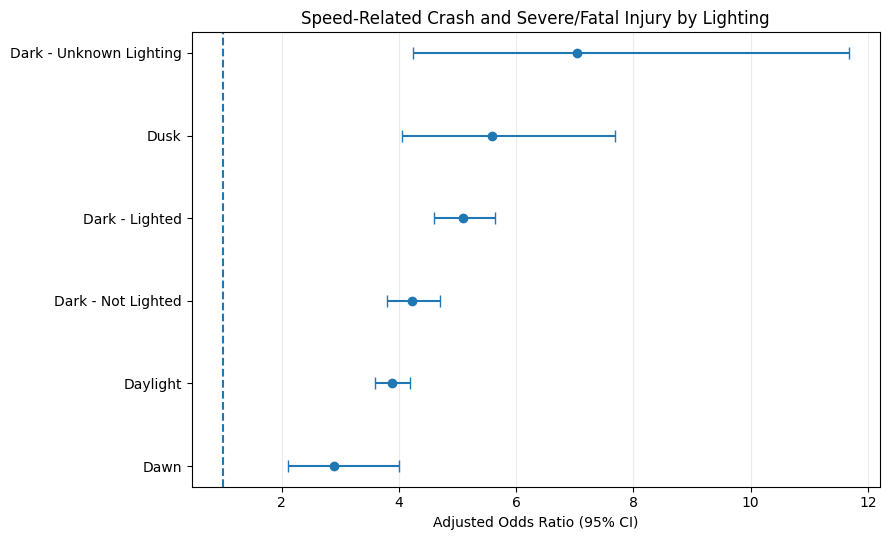

MISSINGNESS IN MERGED ANALYTIC DATA


,Variable,Missing_Count
0,INJ_SEV,0
1,SPEEDREL,0
2,SPEED_RELATED,4203
3,TRAV_SP,0
4,LGT_COND,0
5,AGE_CLEAN,0
6,SEX_LABEL,0


PRIMARY MODEL N: 75806
PRIMARY MODEL UNIQUE CRASHES: 34564
TRAVEL-SPEED MODEL N: 27873
TRAVEL-SPEED UNIQUE CRASHES: 13956
Final result tables and forest plot saved.


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Correct the travel-speed result label
# --------------------------------------------------

travsp_results.loc[
    travsp_results["Variable"].str.contains(
        "Reported travel speed", case=False
    ),
    "Variable"
] = "Reported travel speed: per 10 mph"

print("FINAL TRAVEL-SPEED RESULTS")
display(travsp_results.round(4))


# --------------------------------------------------
# 2. Create a forest plot of lighting-specific ORs
#    from the primary interaction model
# --------------------------------------------------

plot_df = or_original.copy()
plot_df = plot_df.sort_values("Adjusted_OR")

fig, ax = plt.subplots(figsize=(9, 5.5))

y = np.arange(len(plot_df))

ax.errorbar(
    plot_df["Adjusted_OR"],
    y,
    xerr=[
        plot_df["Adjusted_OR"] - plot_df["CI_95_Lower"],
        plot_df["CI_95_Upper"] - plot_df["Adjusted_OR"]
    ],
    fmt="o",
    capsize=4
)

ax.axvline(1, linestyle="--")
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Lighting"])
ax.set_xlabel("Adjusted Odds Ratio (95% CI)")
ax.set_title("Speed-Related Crash and Severe/Fatal Injury by Lighting")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "FARS_Lighting_Forest_Plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# 3. Summarize the analytic data and missingness
# --------------------------------------------------

variables_to_check = [
    "INJ_SEV", "SPEEDREL", "SPEED_RELATED",
    "TRAV_SP", "LGT_COND", "AGE_CLEAN", "SEX_LABEL"
]

diagnostics = pd.DataFrame({
    "Variable": variables_to_check,
    "Missing_Count": [
        analysis_df[v].isna().sum()
        if v in analysis_df.columns
        else model_df[v].isna().sum()
        for v in variables_to_check
    ]
})

print("MISSINGNESS IN MERGED ANALYTIC DATA")
display(diagnostics)

print("PRIMARY MODEL N:", int(model_interaction.nobs))
print("PRIMARY MODEL UNIQUE CRASHES:",
      model_df["ST_CASE"].nunique())

print("TRAVEL-SPEED MODEL N:", int(model_travsp.nobs))
print("TRAVEL-SPEED UNIQUE CRASHES:",
      travsp_df["ST_CASE"].nunique())


# --------------------------------------------------
# 4. Export final tables
# --------------------------------------------------

or_original.to_csv(
    "FARS_Primary_Lighting_ORs.csv", index=False
)

or_sensitivity.to_csv(
    "FARS_Nonlinear_Age_Sensitivity_ORs.csv", index=False
)

model_comparison_final.to_csv(
    "FARS_Final_Model_Comparison.csv", index=False
)

travsp_results.to_csv(
    "FARS_Travel_Speed_Results.csv", index=False
)

diagnostics.to_csv(
    "FARS_Missingness_Diagnostics.csv", index=False
)

print("Final result tables and forest plot saved.")

In [32]:
# FINAL DATA-QUALITY CHECK

# 1. Raw variable code counts
variables = {
    "INJ_SEV": [0, 1, 2, 3, 4, 5, 6, 9],
    "SPEEDREL": [0, 2, 3, 4, 5, 8, 9],
    "TRAV_SP": [0, 997, 998, 999],
    "LGT_COND": [1, 2, 3, 4, 5, 6, 7, 8, 9],
    "AGE": [998, 999],
    "SEX": [1, 2, 8, 9]
}

for var, special_codes in variables.items():
    source = (
        person if var in person.columns
        else vehicle if var in vehicle.columns
        else accident
    )

    if var in source.columns:
        print(f"\n--- {var}: special-code counts ---")
        print(source[var].value_counts(dropna=False).sort_index()
              .loc[lambda x: x.index.isin(special_codes)])


# 2. Missing values in original merged analytic data
print("\n--- Actual missing values in analysis_df ---")
print(
    analysis_df[
        ["INJ_SEV", "SPEEDREL", "TRAV_SP", "LGT_COND", "AGE", "SEX"]
    ].isna().sum()
)


# 3. Sample flow
sample_flow = pd.DataFrame({
    "Stage": [
        "Eligible drivers and passengers",
        "Known speed-related status",
        "Complete-case primary model",
        "Valid reported travel-speed model"
    ],
    "Occupant_records": [
        len(occupant_base),
        int(analysis_df["SPEED_RELATED"].notna().sum()),
        int(model_interaction.nobs),
        int(model_travsp.nobs)
    ]
})

print("\n--- Sample flow ---")
display(sample_flow)

sample_flow.to_csv("FARS_Final_Sample_Flow.csv", index=False)

print("Quality check completed.")


--- INJ_SEV: special-code counts ---
INJ_SEV
0    24285
1     6585
2     9649
3     9563
4    41025
5      200
6        3
9     1458
Name: count, dtype: int64

--- SPEEDREL: special-code counts ---
SPEEDREL
0    43971
2      145
3     4115
4     4555
5     2043
8      366
9     3313
Name: count, dtype: int64

--- TRAV_SP: special-code counts ---
TRAV_SP
0       2483
997        8
998    31357
999     4624
Name: count, dtype: int64

--- LGT_COND: special-code counts ---
LGT_COND
1    16863
2    10255
3     8259
4      727
5      984
6      442
7       17
8       86
9      136
Name: count, dtype: int64

--- AGE: special-code counts ---
AGE
998    1226
999    1135
Name: count, dtype: int64

--- SEX: special-code counts ---
SEX
1    61488
2    29336
8      897
9     1047
Name: count, dtype: int64

--- Actual missing values in analysis_df ---
INJ_SEV     0
SPEEDREL    0
TRAV_SP     0
LGT_COND    0
AGE         0
SEX         0
dtype: int64

--- Sample flow ---


,Stage,Occupant_records
0,Eligible drivers and passengers,81269
1,Known speed-related status,77066
2,Complete-case primary model,75806
3,Valid reported travel-speed model,27873


Quality check completed.


In [33]:
# FINAL ANALYTIC SAMPLE SUMMARY

print("=" * 55)
print("FARS 2023 ANALYSIS — FINAL SAMPLE SUMMARY")
print("=" * 55)

print("\n1. Primary model")
print("Occupant records:", len(model_df))
print("Unique crashes:", model_df["ST_CASE"].nunique())

print("\n2. Injury outcome")
print(model_df["SEVERE_INJURY"].value_counts().sort_index())
print("\nOutcome percentages:")
print(
    (model_df["SEVERE_INJURY"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\n3. Speed-related classification")
print(model_df["SPEED_RELATED"].value_counts().sort_index())
print("\nPercentages:")
print(
    (model_df["SPEED_RELATED"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\n4. Reported travel-speed records")
print("Records used:", len(travsp_df))
print("Unique crashes:", travsp_df["ST_CASE"].nunique())
print("Valid reported speeds:")
print(travsp_df["TRAV_SP_NUM"].describe().round(2))

print("\n5. Lighting categories in primary model")
print(model_df["LIGHTING_MODEL"].value_counts())

print("\n6. Final model convergence")
print("Main-effects model:", model_main.mle_retvals["converged"])
print("Interaction model:", model_interaction.mle_retvals["converged"])
print("Nonlinear age model:", model_sensitivity.mle_retvals["converged"])
print("Travel-speed model:", model_travsp.mle_retvals["converged"])

print("\nSample summary completed.")

FARS 2023 ANALYSIS — FINAL SAMPLE SUMMARY

1. Primary model
Occupant records: 75806
Unique crashes: 34564

2. Injury outcome
SEVERE_INJURY
0    37445
1    38361
Name: count, dtype: int64

Outcome percentages:
SEVERE_INJURY
0    49.4
1    50.6
Name: proportion, dtype: float64

3. Speed-related classification
SPEED_RELATED
0    60654
1    15152
Name: count, dtype: int64

Percentages:
SPEED_RELATED
0    80.01
1    19.99
Name: proportion, dtype: float64

4. Reported travel-speed records
Records used: 27873
Unique crashes: 13956
Valid reported speeds:
count    27873.00
mean        50.93
std         23.21
min          1.00
25%         35.00
50%         53.00
75%         65.00
max        151.00
Name: TRAV_SP_NUM, dtype: float64

5. Lighting categories in primary model
LIGHTING_MODEL
Daylight                   37694
Dark - Not Lighted         18784
Dark - Lighted             15253
Dusk                        2079
Dawn                        1324
Dark - Unknown Lighting      672
Name: count, dt

In [34]:
# FINAL VALIDATION: OUTCOME, SPEED CODING, LIGHTING

print("=" * 60)
print("1. INJURY OUTCOME VALIDATION")
print("=" * 60)

print("Eligible injury codes:")
print(occupant_base["INJ_SEV"].value_counts().sort_index())

print("\nBinary outcome definition:")
print("0 = INJ_SEV codes 0, 1, 2")
print("1 = INJ_SEV codes 3, 4")
print("Codes 5, 6, 9 excluded from the primary outcome sample")


print("\n" + "=" * 60)
print("2. SPEED-RELATED CODING VALIDATION")
print("=" * 60)

print(pd.crosstab(
    analysis_df["SPEEDREL"],
    analysis_df["SPEED_RELATED"],
    margins=True,
    dropna=False
))

print("\nMapping used:")
print("0 -> Not speed-related")
print("2, 3, 4, 5 -> Speed-related")
print("8, 9 -> Unknown / excluded")


print("\n" + "=" * 60)
print("3. LIGHTING AND SPEED DISTRIBUTION")
print("=" * 60)

lighting_speed_summary = (
    model_df.groupby(
        ["LIGHTING_MODEL", "SPEED_RELATED"],
        observed=True
    )
    .agg(
        Occupant_Records=("SEVERE_INJURY", "size"),
        Severe_Fatal_Count=("SEVERE_INJURY", "sum"),
        Severe_Fatal_Percent=("SEVERE_INJURY", "mean")
    )
    .reset_index()
)

lighting_speed_summary["Severe_Fatal_Percent"] *= 100

display(lighting_speed_summary.round(2))

lighting_speed_summary.to_csv(
    "FARS_Final_Lighting_Speed_Summary.csv",
    index=False
)

print("\nValidation summary exported.")

1. INJURY OUTCOME VALIDATION
Eligible injury codes:
INJ_SEV
0    24015
1     6457
2     9436
3     9250
4    32111
Name: count, dtype: int64

Binary outcome definition:
0 = INJ_SEV codes 0, 1, 2
1 = INJ_SEV codes 3, 4
Codes 5, 6, 9 excluded from the primary outcome sample

2. SPEED-RELATED CODING VALIDATION
SPEED_RELATED    0.0    1.0   NaN    All
SPEEDREL                                
0              61657      0     0  61657
2                  0    236     0    236
3                  0   5889     0   5889
4                  0   6405     0   6405
5                  0   2879     0   2879
8                  0      0    69     69
9                  0      0  4134   4134
All            61657  15409     0  81269

Mapping used:
0 -> Not speed-related
2, 3, 4, 5 -> Speed-related
8, 9 -> Unknown / excluded

3. LIGHTING AND SPEED DISTRIBUTION


,LIGHTING_MODEL,SPEED_RELATED,Occupant_Records,Severe_Fatal_Count,Severe_Fatal_Percent
0,Dark - Lighted,0,11604,4204,36.23
1,Dark - Lighted,1,3649,2615,71.66
2,Dark - Not Lighted,0,14620,6605,45.18
3,Dark - Not Lighted,1,4164,3145,75.53
4,Dark - Unknown Lighting,0,506,189,37.35
5,Dark - Unknown Lighting,1,166,130,78.31
6,Dawn,0,1027,518,50.44
7,Dawn,1,297,215,72.39
8,Daylight,0,31228,14833,47.50
9,Daylight,1,6466,4858,75.13



Validation summary exported.


In [35]:
print("PRIMARY MODEL: SPEED-RELATED EFFECT BY LIGHTING")
display(primary_lighting_results.round(3))

print("\nNONLINEAR AGE SENSITIVITY MODEL")
display(nonlinear_age_results.round(3))

print("\nMODEL COMPARISON")
display(model_comparison.round(3))

PRIMARY MODEL: SPEED-RELATED EFFECT BY LIGHTING


NameError: name 'primary_lighting_results' is not defined

In [36]:
import numpy as np
import pandas as pd

def extract_speed_effect_by_lighting(model, model_df):
    lighting_categories = [
        "Dark - Lighted",
        "Dark - Not Lighted",
        "Dark - Unknown Lighting",
        "Dawn",
        "Daylight",
        "Dusk"
    ]

    params = model.params
    cov = model.cov_params()
    rows = []

    for lighting in lighting_categories:
        terms = {"SPEED_RELATED": 1.0}

        if lighting != "Dark - Lighted":
            interaction_term = (
                f"SPEED_RELATED:C(LIGHTING_MODEL)[T.{lighting}]"
            )
            if interaction_term in params.index:
                terms[interaction_term] = 1.0

        log_or = sum(params[name] * weight
                     for name, weight in terms.items())

        variance = 0.0
        for name_i, weight_i in terms.items():
            for name_j, weight_j in terms.items():
                variance += (
                    weight_i * weight_j * cov.loc[name_i, name_j]
                )

        se = np.sqrt(variance)
        lower = log_or - 1.96 * se
        upper = log_or + 1.96 * se

        from scipy.stats import norm
        z = log_or / se
        p_value = 2 * norm.sf(abs(z))

        rows.append({
            "Lighting": lighting,
            "Adjusted_OR": np.exp(log_or),
            "CI_95_Lower": np.exp(lower),
            "CI_95_Upper": np.exp(upper),
            "P_Value": p_value
        })

    return pd.DataFrame(rows)


primary_lighting_results = extract_speed_effect_by_lighting(
    model_interaction, model_df
)

nonlinear_age_results = extract_speed_effect_by_lighting(
    model_sensitivity, model_df
)

print("PRIMARY INTERACTION MODEL")
display(primary_lighting_results.round(4))

print("NONLINEAR AGE SENSITIVITY MODEL")
display(nonlinear_age_results.round(4))

print("MODEL COMPARISON")
model_comparison = pd.DataFrame([
    {
        "Model": "Main effects",
        "N": int(model_main.nobs),
        "AIC": model_main.aic,
        "BIC": model_main.bic,
        "Pseudo_R2": model_main.prsquared
    },
    {
        "Model": "Lighting interaction",
        "N": int(model_interaction.nobs),
        "AIC": model_interaction.aic,
        "BIC": model_interaction.bic,
        "Pseudo_R2": model_interaction.prsquared
    },
    {
        "Model": "Nonlinear age sensitivity",
        "N": int(model_sensitivity.nobs),
        "AIC": model_sensitivity.aic,
        "BIC": model_sensitivity.bic,
        "Pseudo_R2": model_sensitivity.prsquared
    }
])

display(model_comparison.round(4))

PRIMARY INTERACTION MODEL


,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,P_Value
0,Dark - Lighted,5.0950,4.5996,5.6438,0.0
1,Dark - Not Lighted,4.2279,3.7958,4.7092,0.0
2,Dark - Unknown Lighting,7.0322,4.2359,11.6745,0.0
3,Dawn,2.9023,2.1047,4.0023,0.0
4,Daylight,3.8764,3.5891,4.1868,0.0
5,Dusk,5.5845,4.0599,7.6818,0.0


NONLINEAR AGE SENSITIVITY MODEL


,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,P_Value
0,Dark - Lighted,5.0787,4.5849,5.6258,0.0
1,Dark - Not Lighted,4.2071,3.7773,4.6858,0.0
2,Dark - Unknown Lighting,7.0205,4.2264,11.6618,0.0
3,Dawn,2.9097,2.1094,4.0137,0.0
4,Daylight,3.9028,3.6137,4.2151,0.0
5,Dusk,5.6099,4.0791,7.7152,0.0


MODEL COMPARISON


,Model,N,AIC,BIC,Pseudo_R2
0,Main effects,75806,98342.9516,98426.0750,0.0643
1,Lighting interaction,75806,98308.2534,98437.5565,0.0647
2,Nonlinear age sensitivity,75806,98263.5891,98402.1281,0.0651


In [37]:
# FATAL-ONLY SENSITIVITY ANALYSIS

fatal_df = analysis_df.copy()

fatal_df["FATAL_OUTCOME"] = (
    fatal_df["INJ_SEV"] == 4
).astype(int)

fatal_df["AGE_CLEAN"] = fatal_df["AGE"].replace({
    998: np.nan,
    999: np.nan
})

fatal_df["SEX_LABEL"] = fatal_df["SEX"].map({
    1: "Male",
    2: "Female"
})

fatal_df["LIGHTING_MODEL"] = fatal_df["LGT_COND"].map(
    lighting_map
)

fatal_df = fatal_df.dropna(subset=[
    "FATAL_OUTCOME",
    "SPEED_RELATED",
    "AGE_CLEAN",
    "SEX_LABEL",
    "LIGHTING_MODEL"
]).copy()

fatal_formula = (
    "FATAL_OUTCOME ~ SPEED_RELATED * C(LIGHTING_MODEL) "
    "+ AGE_CLEAN + C(SEX_LABEL)"
)

model_fatal = smf.logit(
    formula=fatal_formula,
    data=fatal_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": fatal_df["ST_CASE"]},
    maxiter=200
)

print("Fatal-only sensitivity model")
print("Occupant records:", len(fatal_df))
print("Unique crashes:", fatal_df["ST_CASE"].nunique())
print("Fatal outcome counts:")
print(fatal_df["FATAL_OUTCOME"].value_counts().sort_index())

print(model_fatal.summary())

Optimization terminated successfully.
         Current function value: 0.620452
         Iterations 5
Fatal-only sensitivity model
Occupant records: 75806
Unique crashes: 34564
Fatal outcome counts:
FATAL_OUTCOME
0    46146
1    29660
Name: count, dtype: int64
                           Logit Regression Results                           
Dep. Variable:          FATAL_OUTCOME   No. Observations:                75806
Model:                          Logit   Df Residuals:                    75792
Method:                           MLE   Df Model:                           13
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.07300
Time:                        08:58:26   Log-Likelihood:                -47034.
converged:                       True   LL-Null:                       -50738.
Covariance Type:              cluster   LLR p-value:                     0.000
                                                                 coef    std err          z      P>|z|     

In [38]:
# Joint cluster-robust Wald test of all lighting interactions

interaction_terms_fatal = [
    term for term in model_fatal.params.index
    if "SPEED_RELATED:C(LIGHTING_MODEL)" in term
]

wald_fatal = model_fatal.wald_test(
    " = 0, ".join(interaction_terms_fatal) + " = 0",
    scalar=True
)

print("Fatal-only model: joint interaction test")
print("Chi-square:", float(wald_fatal.statistic))
print("P-value:", float(wald_fatal.pvalue))
print("Degrees of freedom:", len(interaction_terms_fatal))

Fatal-only model: joint interaction test
Chi-square: 9.867705380103885
P-value: 0.0790717233643495
Degrees of freedom: 5


In [39]:
# FINAL DATA-CODING AUDIT

print("=" * 60)
print("FARS 2023 — VARIABLE CODING AUDIT")
print("=" * 60)

print("\n1. INJ_SEV — Injury Severity")
print(person["INJ_SEV"].value_counts(dropna=False).sort_index())

print("\n2. SPEEDREL — Speed-Related Factor")
print(vehicle["SPEEDREL"].value_counts(dropna=False).sort_index())

print("\n3. TRAV_SP — Reported Travel Speed")
print(vehicle["TRAV_SP"].value_counts(dropna=False).sort_index())

print("\n4. LGT_COND — Lighting Condition")
print(accident["LGT_COND"].value_counts(dropna=False).sort_index())

print("\n5. AGE — Person Age")
print(person["AGE"].value_counts(dropna=False).sort_index().tail(15))

print("\n6. SEX — Person Sex")
print(person["SEX"].value_counts(dropna=False).sort_index())

print("\nCoding audit complete.")

FARS 2023 — VARIABLE CODING AUDIT

1. INJ_SEV — Injury Severity
INJ_SEV
0    24285
1     6585
2     9649
3     9563
4    41025
5      200
6        3
9     1458
Name: count, dtype: int64

2. SPEEDREL — Speed-Related Factor
SPEEDREL
0    43971
2      145
3     4115
4     4555
5     2043
8      366
9     3313
Name: count, dtype: int64

3. TRAV_SP — Reported Travel Speed
TRAV_SP
0       2483
1         64
2         37
3         36
4          7
       ...  
150        4
151        1
997        8
998    31357
999     4624
Name: count, Length: 144, dtype: int64

4. LGT_COND — Lighting Condition
LGT_COND
1    16863
2    10255
3     8259
4      727
5      984
6      442
7       17
8       86
9      136
Name: count, dtype: int64

5. AGE — Person Age
AGE
92       55
93       58
94       34
95       25
96       15
97       12
98        2
99        2
100       5
101       4
102       2
103       2
119       1
998    1226
999    1135
Name: count, dtype: int64

6. SEX — Person Sex
SEX
1    61488
2    

In [40]:
# Check whether descriptive code-label columns are available

for name, df in {
    "PERSON": person,
    "VEHICLE": vehicle,
    "ACCIDENT": accident
}.items():
    print(f"\n--- {name} ---")
    print([
        col for col in df.columns
        if any(key in col.upper() for key in [
            "INJ_SEV", "SPEEDREL", "TRAV_SP",
            "LGT_COND", "SEX", "PER_TYP"
        ])
    ])


--- PERSON ---
['SEX', 'SEXNAME', 'PER_TYP', 'PER_TYPNAME', 'INJ_SEV', 'INJ_SEVNAME']

--- VEHICLE ---
['TRAV_SP', 'TRAV_SPNAME', 'SPEEDREL', 'SPEEDRELNAME']

--- ACCIDENT ---
['LGT_COND', 'LGT_CONDNAME']


In [41]:
# FARS 2023 — Code-to-Label Audit

checks = [
    (person, "INJ_SEV", "INJ_SEVNAME", "PERSON: Injury Severity"),
    (person, "SEX", "SEXNAME", "PERSON: Sex"),
    (person, "PER_TYP", "PER_TYPNAME", "PERSON: Person Type"),
    (vehicle, "SPEEDREL", "SPEEDRELNAME", "VEHICLE: Speed-Related"),
    (vehicle, "TRAV_SP", "TRAV_SPNAME", "VEHICLE: Travel Speed"),
    (accident, "LGT_COND", "LGT_CONDNAME", "ACCIDENT: Lighting")
]

for df, code_col, label_col, title in checks:
    print("\n" + "=" * 65)
    print(title)
    print("=" * 65)

    mapping = (
        df[[code_col, label_col]]
        .drop_duplicates()
        .sort_values(code_col)
    )

    print(mapping.to_string(index=False))


PERSON: Injury Severity
 INJ_SEV                  INJ_SEVNAME
       0       No Apparent Injury (O)
       1          Possible Injury (C)
       2   Suspected Minor Injury (B)
       3 Suspected Serious Injury (A)
       4             Fatal Injury (K)
       5    Injured, Severity Unknown
       6         Died Prior to Crash*
       9         Unknown/Not Reported

PERSON: Sex
 SEX             SEXNAME
   1                Male
   2              Female
   8        Not Reported
   9 Reported as Unknown

PERSON: Person Type
 PER_TYP                                            PER_TYPNAME
       1                 Driver of a Motor Vehicle In-Transport
       2              Passenger of a Motor Vehicle In-Transport
       3          Occupant of a Motor Vehicle Not In- Transport
       4       Occupant of a Non-Motor Vehicle Transport Device
       5                                             Pedestrian
       6                                              Bicyclist
       7                  

In [42]:
# FARS 2023 — Final Sample Size Audit

import pandas as pd

datasets_to_check = [
    "occupant_base",
    "analysis_df",
    "model_df",
    "fatal_df"
]

for name in datasets_to_check:
    df = globals().get(name)

    if isinstance(df, pd.DataFrame):
        print("\n" + "=" * 55)
        print(f"DATASET: {name}")
        print("=" * 55)
        print("Rows (occupant records):", len(df))

        if "ST_CASE" in df.columns:
            print("Unique crashes:", df["ST_CASE"].nunique())

        if "PER_NO" in df.columns:
            print("Unique person IDs:", df["PER_NO"].nunique())

        if "SEVERE_INJURY" in df.columns:
            print("\nSevere/fatal outcome:")
            print(df["SEVERE_INJURY"].value_counts(dropna=False).sort_index())

        if "FATAL_OUTCOME" in df.columns:
            print("\nFatal-only outcome:")
            print(df["FATAL_OUTCOME"].value_counts(dropna=False).sort_index())

        if "SPEED_RELATED" in df.columns:
            print("\nSpeed-related status:")
            print(df["SPEED_RELATED"].value_counts(dropna=False).sort_index())

    else:
        print(f"\n{name}: DataFrame not currently available")


DATASET: occupant_base
Rows (occupant records): 81269
Unique crashes: 36996
Unique person IDs: 49

Severe/fatal outcome:
SEVERE_INJURY
0    39908
1    41361
Name: count, dtype: int64

DATASET: analysis_df
Rows (occupant records): 81269
Unique crashes: 36996
Unique person IDs: 49

Severe/fatal outcome:
SEVERE_INJURY
0    39908
1    41361
Name: count, dtype: int64

Speed-related status:
SPEED_RELATED
0.0    61657
1.0    15409
NaN     4203
Name: count, dtype: int64

DATASET: model_df
Rows (occupant records): 75806
Unique crashes: 34564
Unique person IDs: 49

Severe/fatal outcome:
SEVERE_INJURY
0    37445
1    38361
Name: count, dtype: int64

Speed-related status:
SPEED_RELATED
0    60654
1    15152
Name: count, dtype: int64

DATASET: fatal_df
Rows (occupant records): 75806
Unique crashes: 34564
Unique person IDs: 49

Severe/fatal outcome:
SEVERE_INJURY
0    37445
1    38361
Name: count, dtype: int64

Fatal-only outcome:
FATAL_OUTCOME
0    46146
1    29660
Name: count, dtype: int64

Speed

In [43]:

import numpy as np
import pandas as pd
from pathlib import Path

# Use the existing output folder from your current notebook.
TABLE_DIR = Path("/content/FARS_2023_Research/outputs/tables")
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# TABLE 1: Sample characteristics by speed status
# --------------------------------------------------

def categorical_summary(data, variable, group="SPEED_LABEL"):
    counts = pd.crosstab(data[group], data[variable], dropna=False)
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100

    rows = []
    for group_value in counts.index:
        for category in counts.columns:
            rows.append({
                "Speed_group": group_value,
                "Variable": variable,
                "Category": str(category),
                "N": int(counts.loc[group_value, category]),
                "Percent_within_group": round(
                    percentages.loc[group_value, category], 2
                )
            })

    return pd.DataFrame(rows)


table1_parts = []

for variable in [
    "LIGHTING_MODEL",
    "SEX_LABEL",
    "SEVERE_INJURY"
]:
    table1_parts.append(
        categorical_summary(model_df, variable)
    )

table1_categorical = pd.concat(
    table1_parts, ignore_index=True
)

age_summary = (
    model_df.groupby("SPEED_LABEL", observed=False)
    .agg(
        N=("AGE_CLEAN", "count"),
        Mean_age=("AGE_CLEAN", "mean"),
        SD_age=("AGE_CLEAN", "std"),
        Median_age=("AGE_CLEAN", "median")
    )
    .reset_index()
)

age_summary.to_csv(
    TABLE_DIR / "Table1_Age_Summary.csv", index=False
)

table1_categorical.to_csv(
    TABLE_DIR / "Table1_Sample_Characteristics.csv",
    index=False
)

# --------------------------------------------------
# TABLE 2: Consolidated regression coefficients
# --------------------------------------------------

model_objects = {
    "Primary main effects": primary_main,
    "Primary speed-lighting interaction": primary_interaction,
    "Nonlinear age sensitivity": nonlinear_age_model,
    "Recorded travel speed sensitivity": travel_model,
    "Fatal-outcome sensitivity": fatal_model
}

regression_rows = []

for model_name, result in model_objects.items():
    ci = result.conf_int()

    for term in result.params.index:
        beta = result.params[term]
        se = result.bse[term]

        regression_rows.append({
            "Model": model_name,
            "Term": term,
            "Coefficient": beta,
            "SE_cluster_robust": se,
            "Adjusted_OR": np.exp(beta),
            "CI_95_lower": np.exp(ci.loc[term, 0]),
            "CI_95_upper": np.exp(ci.loc[term, 1]),
            "P_value": result.pvalues[term],
            "N_occupants": int(result.nobs)
        })

table2 = pd.DataFrame(regression_rows)

table2.to_csv(
    TABLE_DIR / "Table2_Consolidated_Regression_Results.csv",
    index=False
)

# --------------------------------------------------
# TABLE 3: Compare lighting-specific speed ORs
# --------------------------------------------------

primary_compare = lighting_ors.copy()
primary_compare["Outcome_model"] = "Severe/fatal injury"

fatal_compare = fatal_lighting_ors.copy()
fatal_compare["Outcome_model"] = "Fatal injury only"

table3 = pd.concat(
    [primary_compare, fatal_compare],
    ignore_index=True
)

table3.to_csv(
    TABLE_DIR / "Table3_Lighting_OR_Outcome_Comparison.csv",
    index=False
)

# --------------------------------------------------
# TABLE 4: Variable definitions and interpretation
# --------------------------------------------------

codebook = pd.DataFrame([
    {
        "Variable": "SEVERE_INJURY",
        "Definition": "INJ_SEV 3-4 versus 0-2",
        "Interpretation": "Severe or fatal injury versus non-severe"
    },
    {
        "Variable": "FATAL_OUTCOME",
        "Definition": "INJ_SEV 4 versus INJ_SEV 0-3",
        "Interpretation": "Fatal injury versus non-fatal injury"
    },
    {
        "Variable": "SPEED_RELATED",
        "Definition": "SPEEDREL 2-5 versus 0",
        "Interpretation": "Speed-related versus not speed-related"
    },
    {
        "Variable": "LIGHTING_MODEL",
        "Definition": "LGT_COND 1-6 mapped to lighting categories",
        "Interpretation": "Reference category: Dark - Lighted"
    },
    {
        "Variable": "AGE_CLEAN",
        "Definition": "AGE values 0-120 retained",
        "Interpretation": "Age in years"
    },
    {
        "Variable": "TRAV_SP_NUM",
        "Definition": "Recorded travel speed from 1-151 mph",
        "Interpretation": "Secondary model; recorded speed is not available for all records"
    },
    {
        "Variable": "ST_CASE",
        "Definition": "Crash identifier",
        "Interpretation": "Cluster identifier for robust standard errors"
    }
])

codebook.to_csv(
    TABLE_DIR / "Table4_Variable_Codebook.csv",
    index=False
)

print("New publication-style tables saved.")
print("Table 1: Sample characteristics")
print("Table 2: Consolidated regression results")
print("Table 3: Lighting OR comparison")
print("Table 4: Variable codebook")


KeyError: 'SPEED_LABEL'

In [44]:

# Check the relevant columns first
print("SPEED_RELATED exists:", "SPEED_RELATED" in model_df.columns)
print("SPEED_LABEL exists:", "SPEED_LABEL" in model_df.columns)

# Recreate the missing label from the existing model variable
if "SPEED_RELATED" not in model_df.columns:
    raise KeyError(
        "SPEED_RELATED column is also missing. "
        "Please show the output of print(model_df.columns.tolist())."
    )

model_df["SPEED_LABEL"] = model_df["SPEED_RELATED"].map({
    0: "Not speed-related",
    1: "Speed-related"
})

print(model_df["SPEED_LABEL"].value_counts(dropna=False))


SPEED_RELATED exists: True
SPEED_LABEL exists: False
SPEED_LABEL
Not speed-related    60654
Speed-related        15152
Name: count, dtype: int64


In [45]:
print(model_df.columns.tolist())

['STATE', 'STATENAME', 'ST_CASE', 'VEH_NO', 'PER_NO', 'VE_FORMS', 'COUNTY', 'MONTH', 'MONTHNAME', 'DAY', 'DAYNAME', 'HOUR', 'HOURNAME', 'MINUTE', 'MINUTENAME', 'HARM_EV', 'HARM_EVNAME', 'MAN_COLL', 'MAN_COLLNAME', 'SCH_BUS', 'SCH_BUSNAME', 'RUR_URB', 'RUR_URBNAME', 'FUNC_SYS', 'FUNC_SYSNAME', 'MOD_YEAR', 'MOD_YEARNAME', 'VPICMAKE', 'VPICMAKENAME', 'VPICMODEL', 'VPICMODELNAME', 'VPICBODYCLASS', 'VPICBODYCLASSNAME', 'MAKE', 'MAKENAME', 'BODY_TYP', 'BODY_TYPNAME', 'ICFINALBODY', 'ICFINALBODYNAME', 'GVWR_FROM', 'GVWR_FROMNAME', 'GVWR_TO', 'GVWR_TONAME', 'TOW_VEH', 'TOW_VEHNAME', 'SPEC_USE', 'SPEC_USENAME', 'EMER_USE', 'EMER_USENAME', 'ROLLOVER', 'ROLLOVERNAME', 'IMPACT1', 'IMPACT1NAME', 'FIRE_EXP', 'FIRE_EXPNAME', 'MAK_MOD', 'MAK_MODNAME', 'AGE', 'AGENAME', 'SEX', 'SEXNAME', 'PER_TYP', 'PER_TYPNAME', 'INJ_SEV', 'INJ_SEVNAME', 'SEAT_POS', 'SEAT_POSNAME', 'REST_USE', 'REST_USENAME', 'REST_MIS', 'REST_MISNAME', 'HELM_USE', 'HELM_USENAME', 'HELM_MIS', 'HELM_MISNAME', 'AIR_BAG', 'AIR_BAGNAME', 

In [46]:
# Verify the variables needed for the additional tables
print("SPEED_LABEL:", model_df["SPEED_LABEL"].value_counts(dropna=False))
print("\nSPEED_RELATED_LABEL:")
print(model_df["SPEED_RELATED_LABEL"].value_counts(dropna=False))

print("\nLighting categories:")
print(model_df["LIGHTING_MODEL"].value_counts(dropna=False))

print("\nOutcome categories:")
print(model_df["SEVERE_INJURY"].value_counts(dropna=False))

SPEED_LABEL: SPEED_LABEL
Not speed-related    60654
Speed-related        15152
Name: count, dtype: int64

SPEED_RELATED_LABEL:
SPEED_RELATED_LABEL
Not speed-related    60654
Speed-related        15152
Name: count, dtype: int64

Lighting categories:
LIGHTING_MODEL
Daylight                   37694
Dark - Not Lighted         18784
Dark - Lighted             15253
Dusk                        2079
Dawn                        1324
Dark - Unknown Lighting      672
Name: count, dtype: int64

Outcome categories:
SEVERE_INJURY
1    38361
0    37445
Name: count, dtype: int64


TABLE 1: Injury severity by speed-related status


,SPEED_LABEL,Total_occupants,Non_severe,Non_severe_percent,Severe_or_fatal,Severe_fatal_percent
0,Not speed-related,60654,33582,55.37,27072,44.63
1,Speed-related,15152,3863,25.49,11289,74.51



TABLE 2: Injury severity by lighting and speed status


,LIGHTING_MODEL,SPEED_LABEL,Total_occupants,Severe_or_fatal,Severe_fatal_percent,Non_severe
0,Dark - Lighted,Not speed-related,11604,4204,36.23,7400
1,Dark - Lighted,Speed-related,3649,2615,71.66,1034
2,Dark - Not Lighted,Not speed-related,14620,6605,45.18,8015
3,Dark - Not Lighted,Speed-related,4164,3145,75.53,1019
4,Dark - Unknown Lighting,Not speed-related,506,189,37.35,317
5,Dark - Unknown Lighting,Speed-related,166,130,78.31,36
6,Dawn,Not speed-related,1027,518,50.44,509
7,Dawn,Speed-related,297,215,72.39,82
8,Daylight,Not speed-related,31228,14833,47.50,16395
9,Daylight,Speed-related,6466,4858,75.13,1608


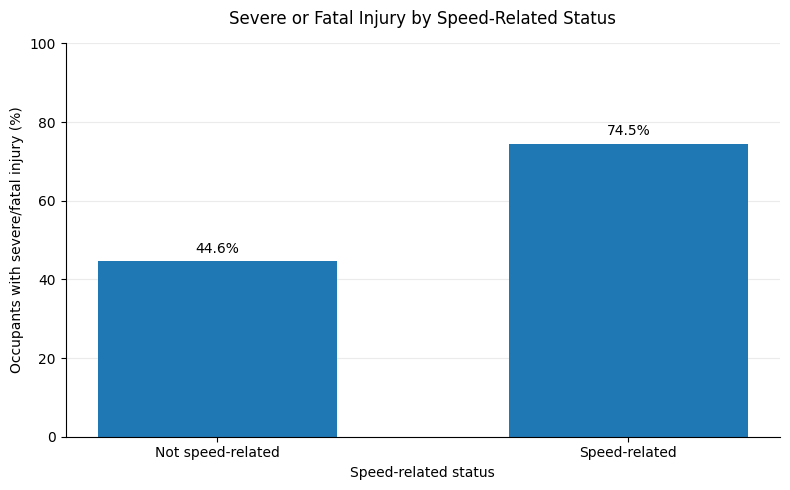


Files saved in: /content/FARS_Research_Outputs
- Figure_01_Injury_Severity_by_Speed.png
- Table_Injury_Severity_by_Lighting_and_Speed.csv
- Table_Injury_Severity_by_Speed_Status.csv


In [47]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder for the new GitHub repository
output_dir = Path("FARS_Research_Outputs")
output_dir.mkdir(exist_ok=True)

# Work with the existing final analysis sample
df = model_df.copy()

# Confirm the required columns exist
required = [
    "SPEED_LABEL", "LIGHTING_MODEL", "SEVERE_INJURY"
]
missing = [col for col in required if col not in df.columns]

if missing:
    raise KeyError(f"Missing required columns: {missing}")

# ------------------------------------------
# TABLE 1: Injury severity by speed status
# ------------------------------------------
speed_table = (
    df.groupby("SPEED_LABEL", observed=True)
      .agg(
          Total_occupants=("SEVERE_INJURY", "size"),
          Severe_or_fatal=("SEVERE_INJURY", "sum")
      )
      .reset_index()
)

speed_table["Non_severe"] = (
    speed_table["Total_occupants"] - speed_table["Severe_or_fatal"]
)

speed_table["Severe_fatal_percent"] = (
    100 * speed_table["Severe_or_fatal"] /
    speed_table["Total_occupants"]
).round(2)

speed_table["Non_severe_percent"] = (
    100 * speed_table["Non_severe"] /
    speed_table["Total_occupants"]
).round(2)

speed_table = speed_table[
    [
        "SPEED_LABEL",
        "Total_occupants",
        "Non_severe",
        "Non_severe_percent",
        "Severe_or_fatal",
        "Severe_fatal_percent"
    ]
]

speed_table.to_csv(
    output_dir / "Table_Injury_Severity_by_Speed_Status.csv",
    index=False
)

print("TABLE 1: Injury severity by speed-related status")
display(speed_table)


# ------------------------------------------------
# TABLE 2: Injury severity by lighting and speed
# ------------------------------------------------
lighting_speed_table = (
    df.groupby(
        ["LIGHTING_MODEL", "SPEED_LABEL"],
        observed=True
    )
    .agg(
        Total_occupants=("SEVERE_INJURY", "size"),
        Severe_or_fatal=("SEVERE_INJURY", "sum")
    )
    .reset_index()
)

lighting_speed_table["Severe_fatal_percent"] = (
    100 * lighting_speed_table["Severe_or_fatal"] /
    lighting_speed_table["Total_occupants"]
).round(2)

lighting_speed_table["Non_severe"] = (
    lighting_speed_table["Total_occupants"] -
    lighting_speed_table["Severe_or_fatal"]
)

lighting_speed_table.to_csv(
    output_dir / "Table_Injury_Severity_by_Lighting_and_Speed.csv",
    index=False
)

print("\nTABLE 2: Injury severity by lighting and speed status")
display(lighting_speed_table)


# ----------------------------------------------------
# FIGURE 1: Severe/fatal injury percentage by speed
# ----------------------------------------------------
plot_data = speed_table.set_index("SPEED_LABEL")[
    "Severe_fatal_percent"
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_data.index,
    plot_data.values,
    width=0.58
)

ax.set_title(
    "Severe or Fatal Injury by Speed-Related Status",
    pad=14
)
ax.set_ylabel("Occupants with severe/fatal injury (%)")
ax.set_xlabel("Speed-related status")
ax.set_ylim(0, 100)

ax.bar_label(
    bars,
    labels=[f"{v:.1f}%" for v in plot_data.values],
    padding=4
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    output_dir / "Figure_01_Injury_Severity_by_Speed.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------
# Report the output files created
# ------------------------------------------
print("\nFiles saved in:", output_dir.resolve())

for file_path in sorted(output_dir.iterdir()):
    print("-", file_path.name)


In [48]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("FARS_Research_Outputs")
output_dir.mkdir(exist_ok=True)

# Inspect the existing results object before plotting
print("Object type:", type(lighting_ors))
print("Columns:", getattr(lighting_ors, "columns", "No columns attribute"))

display(lighting_ors)


NameError: name 'lighting_ors' is not defined

In [49]:

# Check which existing analysis results are available
candidate_names = [
    "model_df",
    "primary_main",
    "primary_interaction",
    "nonlinear_age_model",
    "travel_model",
    "fatal_model",
    "lighting_ors",
    "fatal_lighting_ors",
    "nonlinear_age_ors"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: available | type = {type(obj).__name__}")
        if isinstance(obj, pd.DataFrame):
            print("  columns:", obj.columns.tolist())
    else:
        print(f"{name}: not available")


model_df: available | type = DataFrame
  columns: ['STATE', 'STATENAME', 'ST_CASE', 'VEH_NO', 'PER_NO', 'VE_FORMS', 'COUNTY', 'MONTH', 'MONTHNAME', 'DAY', 'DAYNAME', 'HOUR', 'HOURNAME', 'MINUTE', 'MINUTENAME', 'HARM_EV', 'HARM_EVNAME', 'MAN_COLL', 'MAN_COLLNAME', 'SCH_BUS', 'SCH_BUSNAME', 'RUR_URB', 'RUR_URBNAME', 'FUNC_SYS', 'FUNC_SYSNAME', 'MOD_YEAR', 'MOD_YEARNAME', 'VPICMAKE', 'VPICMAKENAME', 'VPICMODEL', 'VPICMODELNAME', 'VPICBODYCLASS', 'VPICBODYCLASSNAME', 'MAKE', 'MAKENAME', 'BODY_TYP', 'BODY_TYPNAME', 'ICFINALBODY', 'ICFINALBODYNAME', 'GVWR_FROM', 'GVWR_FROMNAME', 'GVWR_TO', 'GVWR_TONAME', 'TOW_VEH', 'TOW_VEHNAME', 'SPEC_USE', 'SPEC_USENAME', 'EMER_USE', 'EMER_USENAME', 'ROLLOVER', 'ROLLOVERNAME', 'IMPACT1', 'IMPACT1NAME', 'FIRE_EXP', 'FIRE_EXPNAME', 'MAK_MOD', 'MAK_MODNAME', 'AGE', 'AGENAME', 'SEX', 'SEXNAME', 'PER_TYP', 'PER_TYPNAME', 'INJ_SEV', 'INJ_SEVNAME', 'SEAT_POS', 'SEAT_POSNAME', 'REST_USE', 'REST_USENAME', 'REST_MIS', 'REST_MISNAME', 'HELM_USE', 'HELM_USENAME', 'HEL

In [50]:

from pathlib import Path

# Search common Colab locations for previously exported results
search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

keywords = [
    "FARS_Primary_Lighting_ORs.csv",
    "FARS_Nonlinear_Age_Sensitivity_ORs.csv",
    "FARS_Final_Model_Comparison.csv",
    "FARS_Travel_Speed_Results.csv",
    "FARS_Missingness_Diagnostics.csv",
    "FARS_Final_Sample_Flow.csv",
    "FARS_Final_Lighting_Speed_Summary.csv"
]

found = []

for root in search_roots:
    if root.exists():
        for file in root.rglob("*.csv"):
            if file.name in keywords:
                found.append(file)

if found:
    print("Previously exported result files found:")
    for file in found:
        print(file)
else:
    print("No matching CSV files found in the searched locations.")
    print("If your Google Drive is not mounted, we can check that next.")


Previously exported result files found:
/content/FARS_Nonlinear_Age_Sensitivity_ORs.csv
/content/FARS_Missingness_Diagnostics.csv
/content/FARS_Final_Lighting_Speed_Summary.csv
/content/FARS_Final_Sample_Flow.csv
/content/FARS_Travel_Speed_Results.csv
/content/FARS_Final_Model_Comparison.csv
/content/FARS_Primary_Lighting_ORs.csv


In [51]:

import pandas as pd
from pathlib import Path

files = [
    "FARS_Primary_Lighting_ORs.csv",
    "FARS_Nonlinear_Age_Sensitivity_ORs.csv",
    "FARS_Final_Model_Comparison.csv",
    "FARS_Travel_Speed_Results.csv"
]

for filename in files:
    path = Path("/content") / filename

    print("\n" + "=" * 70)
    print("FILE:", filename)

    result = pd.read_csv(path)

    print("Columns:", result.columns.tolist())
    display(result.head(5))



FILE: FARS_Primary_Lighting_ORs.csv
Columns: ['Model', 'Lighting', 'Adjusted_OR', 'CI_95_Lower', 'CI_95_Upper', 'p_value']


,Model,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,p_value
0,Original interaction,Dark - Lighted,5.095026,4.599633,5.643774,1.063351e-213
1,Original interaction,Dark - Not Lighted,4.227896,3.795782,4.709201,2.075728e-151
2,Original interaction,Dark - Unknown Lighting,7.032217,4.235904,11.674505,4.634936e-14
3,Original interaction,Dawn,2.902346,2.104707,4.002272,8.083775e-11
4,Original interaction,Daylight,3.876408,3.589064,4.186757,1.558230e-260



FILE: FARS_Nonlinear_Age_Sensitivity_ORs.csv
Columns: ['Model', 'Lighting', 'Adjusted_OR', 'CI_95_Lower', 'CI_95_Upper', 'p_value']


,Model,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,p_value
0,Nonlinear age sensitivity,Dark - Lighted,5.078726,4.584892,5.625751,7.618695e-213
1,Nonlinear age sensitivity,Dark - Not Lighted,4.207084,3.777291,4.685779,1.571349e-150
2,Nonlinear age sensitivity,Dark - Unknown Lighting,7.020537,4.226446,11.661792,5.196849e-14
3,Nonlinear age sensitivity,Dawn,2.909740,2.109442,4.013662,7.589121e-11
4,Nonlinear age sensitivity,Daylight,3.902792,3.613665,4.215052,1.881586e-263



FILE: FARS_Final_Model_Comparison.csv
Columns: ['Model', 'N', 'AIC', 'BIC', 'Pseudo_R2', 'Log_Likelihood']


,Model,N,AIC,BIC,Pseudo_R2,Log_Likelihood
0,Main effects,75806,98342.951571,98426.074966,0.064270,-49162.475786
1,Interaction,75806,98308.253450,98437.556508,0.064696,-49140.126725
2,Nonlinear age sensitivity,75806,98263.589126,98402.128117,0.065140,-49116.794563



FILE: FARS_Travel_Speed_Results.csv
Columns: ['Variable', 'OR', 'CI_95_Lower', 'CI_95_Upper', 'p_value']


,Variable,OR,CI_95_Lower,CI_95_Upper,p_value
0,Speed-related crash: Yes vs No,2.934682,2.671174,3.224185,2.057229e-111
1,Reported travel speed: per 10 mph,1.212542,1.192262,1.233168,4.440442e-111


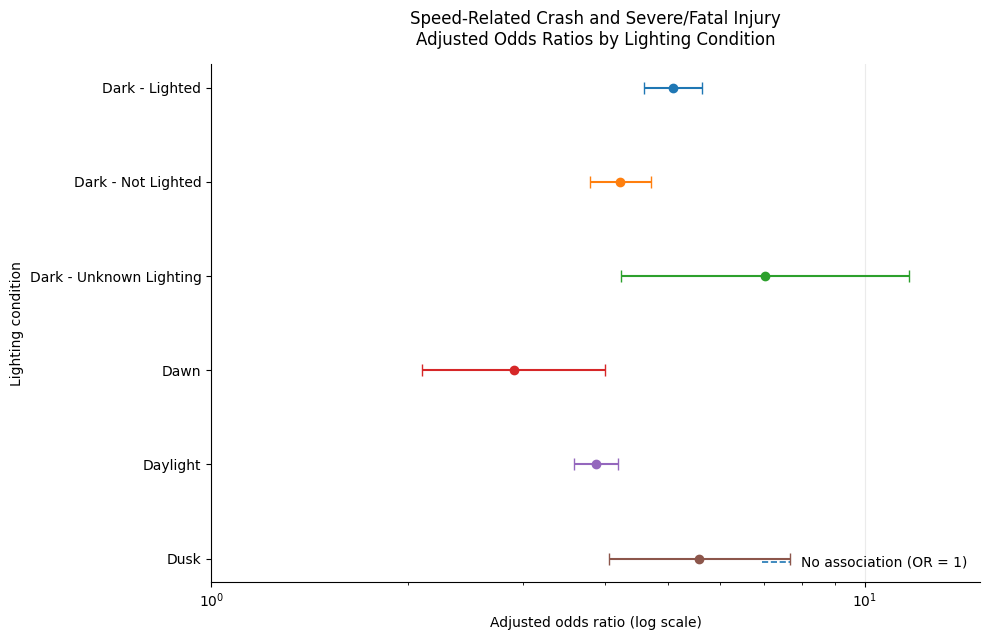

Forest plot saved to: /content/FARS_Research_Outputs/Figure_02_Adjusted_OR_Forest_Plot.png
Source data saved to: /content/FARS_Research_Outputs/Figure_02_Forest_Plot_Source_Data.csv


In [52]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folder for research outputs
output_dir = Path("/content/FARS_Research_Outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Load saved primary-model results
ors = pd.read_csv("/content/FARS_Primary_Lighting_ORs.csv")

# Keep the original interaction model
primary = ors[
    ors["Model"].astype(str).str.contains(
        "Original interaction", case=False, na=False
    )
].copy()

if primary.empty:
    raise ValueError(
        "No rows for 'Original interaction' found. "
        "Inspect ors['Model'].unique() before proceeding."
    )

# Validate required fields
required_cols = [
    "Lighting", "Adjusted_OR", "CI_95_Lower",
    "CI_95_Upper", "p_value"
]
missing_cols = [c for c in required_cols if c not in primary.columns]

if missing_cols:
    raise KeyError(f"Missing columns: {missing_cols}")

# Set a readable order for lighting conditions
lighting_order = [
    "Dark - Lighted",
    "Dark - Not Lighted",
    "Dark - Unknown Lighting",
    "Dawn",
    "Daylight",
    "Dusk"
]

primary["Lighting"] = pd.Categorical(
    primary["Lighting"],
    categories=lighting_order,
    ordered=True
)
primary = primary.sort_values("Lighting").dropna(
    subset=["Lighting", "Adjusted_OR", "CI_95_Lower", "CI_95_Upper"]
)

# Export the exact data used in the figure
primary.to_csv(
    output_dir / "Figure_02_Forest_Plot_Source_Data.csv",
    index=False
)

# Forest plot
plot_df = primary.reset_index(drop=True)
y_positions = list(range(len(plot_df)))

fig, ax = plt.subplots(figsize=(10, 6.5))

for y, (_, row) in zip(y_positions, plot_df.iterrows()):
    ax.errorbar(
        x=row["Adjusted_OR"],
        y=y,
        xerr=[[
            row["Adjusted_OR"] - row["CI_95_Lower"]
        ], [
            row["CI_95_Upper"] - row["Adjusted_OR"]
        ]],
        fmt="o",
        capsize=4,
        markersize=6,
        linewidth=1.5
    )

ax.axvline(
    x=1,
    linestyle="--",
    linewidth=1.2,
    label="No association (OR = 1)"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_df["Lighting"].astype(str))
ax.invert_yaxis()

# Log scale is standard for odds-ratio forest plots
ax.set_xscale("log")
ax.set_xlim(1, max(15, plot_df["CI_95_Upper"].max() * 1.15))

ax.set_xlabel("Adjusted odds ratio (log scale)")
ax.set_ylabel("Lighting condition")
ax.set_title(
    "Speed-Related Crash and Severe/Fatal Injury\n"
    "Adjusted Odds Ratios by Lighting Condition",
    pad=14
)

ax.grid(axis="x", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()

figure_path = output_dir / "Figure_02_Adjusted_OR_Forest_Plot.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Forest plot saved to:", figure_path)
print("Source data saved to:",
      output_dir / "Figure_02_Forest_Plot_Source_Data.csv")


Available columns: ['Model', 'N', 'AIC', 'BIC', 'Pseudo_R2', 'Log_Likelihood']


,Model,N,AIC,BIC,Pseudo_R2,Log_Likelihood
0,Main effects,75806,98342.951571,98426.074966,0.064270,-49162.475786
1,Interaction,75806,98308.253450,98437.556508,0.064696,-49140.126725
2,Nonlinear age sensitivity,75806,98263.589126,98402.128117,0.065140,-49116.794563



Publication-ready model comparison table:


,Model,N,AIC,BIC,Pseudo_R2,Log_Likelihood
0,Main effects,75806,98342.95,98426.07,0.0643,-49162.48
1,Interaction,75806,98308.25,98437.56,0.0647,-49140.13
2,Nonlinear age sensitivity,75806,98263.59,98402.13,0.0651,-49116.79


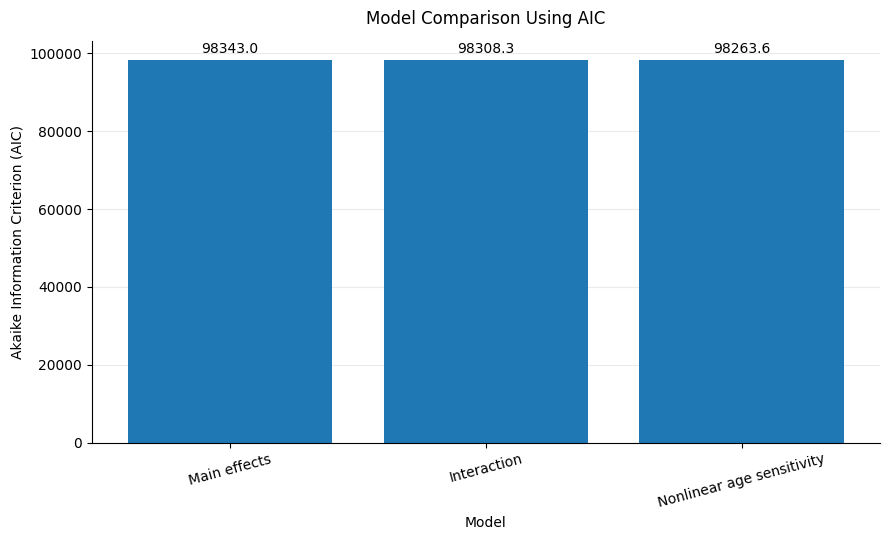


Saved outputs:
Table_Model_Comparison.csv | exists: True
Figure_03_Model_Comparison_AIC.png | exists: True


In [53]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("/content/FARS_Research_Outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Load the saved model comparison results
comparison = pd.read_csv("/content/FARS_Final_Model_Comparison.csv")

print("Available columns:", comparison.columns.tolist())
display(comparison)

# Create a clean publication table
comparison_table = comparison.copy()

for col in ["AIC", "BIC", "Pseudo_R2", "Log_Likelihood"]:
    if col in comparison_table.columns:
        comparison_table[col] = pd.to_numeric(
            comparison_table[col], errors="coerce"
        )

# Round numerical columns for readability
for col in ["AIC", "BIC", "Log_Likelihood"]:
    if col in comparison_table.columns:
        comparison_table[col] = comparison_table[col].round(2)

if "Pseudo_R2" in comparison_table.columns:
    comparison_table["Pseudo_R2"] = (
        comparison_table["Pseudo_R2"].round(4)
    )

comparison_table.to_csv(
    output_dir / "Table_Model_Comparison.csv",
    index=False
)

print("\nPublication-ready model comparison table:")
display(comparison_table)

# Figure: compare AIC across models
if {"Model", "AIC"}.issubset(comparison.columns):
    plot_df = comparison.copy()
    plot_df["AIC"] = pd.to_numeric(plot_df["AIC"], errors="coerce")
    plot_df = plot_df.dropna(subset=["Model", "AIC"])

    fig, ax = plt.subplots(figsize=(9, 5.5))
    bars = ax.bar(plot_df["Model"], plot_df["AIC"])

    ax.set_title("Model Comparison Using AIC", pad=12)
    ax.set_ylabel("Akaike Information Criterion (AIC)")
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=15)
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    fig.tight_layout()
    fig.savefig(
        output_dir / "Figure_03_Model_Comparison_AIC.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("\nSaved outputs:")
for filename in [
    "Table_Model_Comparison.csv",
    "Figure_03_Model_Comparison_AIC.png"
]:
    path = output_dir / filename
    print(filename, "| exists:", path.exists())


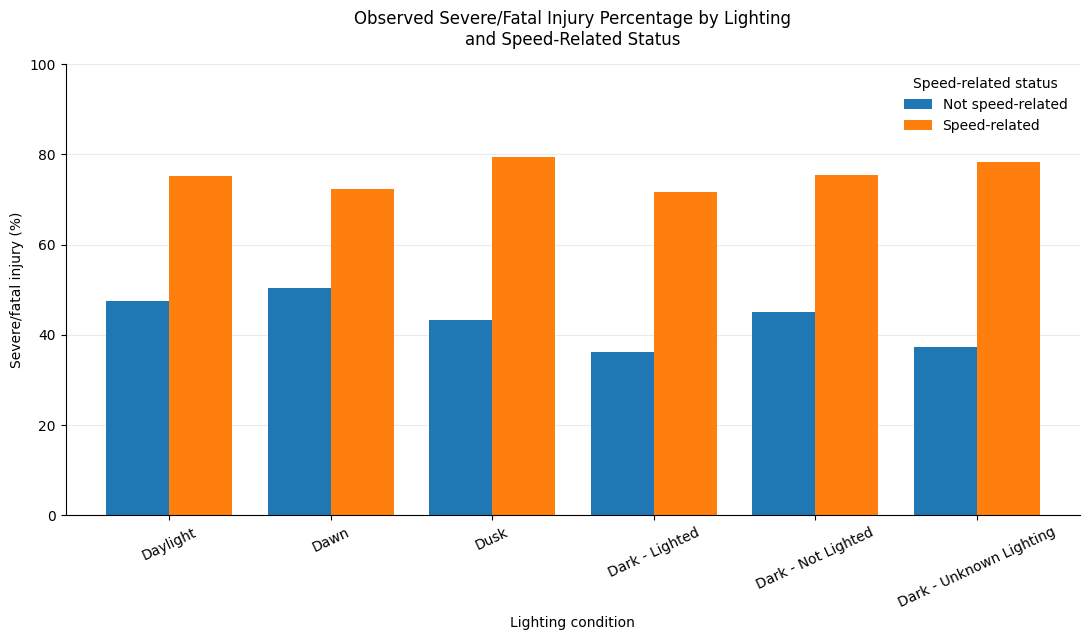

Saved grouped bar chart and its source data.


In [54]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

out = Path("/content/FARS_Research_Outputs")
out.mkdir(parents=True, exist_ok=True)

# Calculate observed severe/fatal injury percentage
plot_df = (
    model_df.groupby(
        ["LIGHTING_MODEL", "SPEED_LABEL"],
        observed=True
    )
    .agg(
        Total=("SEVERE_INJURY", "size"),
        Severe_Fatal=("SEVERE_INJURY", "sum")
    )
    .reset_index()
)

plot_df["Severe_Fatal_Percent"] = (
    100 * plot_df["Severe_Fatal"] / plot_df["Total"]
)

lighting_order = [
    "Daylight",
    "Dawn",
    "Dusk",
    "Dark - Lighted",
    "Dark - Not Lighted",
    "Dark - Unknown Lighting"
]

speed_order = ["Not speed-related", "Speed-related"]

pivot = plot_df.pivot(
    index="LIGHTING_MODEL",
    columns="SPEED_LABEL",
    values="Severe_Fatal_Percent"
).reindex(lighting_order)

pivot = pivot.reindex(columns=speed_order)

fig, ax = plt.subplots(figsize=(11, 6.5))

pivot.plot(
    kind="bar",
    ax=ax,
    width=0.78
)

ax.set_title(
    "Observed Severe/Fatal Injury Percentage by Lighting\n"
    "and Speed-Related Status",
    pad=14
)
ax.set_xlabel("Lighting condition")
ax.set_ylabel("Severe/fatal injury (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Speed-related status", frameon=False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(
    out / "Figure_04_Grouped_Bar_Injury_Percentage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save the plotted percentages and counts
plot_df.to_csv(
    out / "Figure_04_Grouped_Bar_Source_Data.csv",
    index=False
)

print("Saved grouped bar chart and its source data.")


In [55]:

import os
import pandas as pd

folder = "/content/FARS_Research_Outputs"

files_to_check = [
    "/content/FARS_Final_Sample_Flow.csv",
    "/content/FARS_Missingness_Diagnostics.csv",
]

for file_path in files_to_check:
    print("\n" + "=" * 70)
    print("FILE:", os.path.basename(file_path))

    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        print("Columns:", df.columns.tolist())
        display(df)
    else:
        print("File not found:", file_path)

print("\nOutput folder files:")
if os.path.exists(folder):
    print("\n".join(os.listdir(folder)))
else:
    print("Output folder not found.")



FILE: FARS_Final_Sample_Flow.csv
Columns: ['Stage', 'Occupant_records']


,Stage,Occupant_records
0,Eligible drivers and passengers,81269
1,Known speed-related status,77066
2,Complete-case primary model,75806
3,Valid reported travel-speed model,27873



FILE: FARS_Missingness_Diagnostics.csv
Columns: ['Variable', 'Missing_Count']


,Variable,Missing_Count
0,INJ_SEV,0
1,SPEEDREL,0
2,SPEED_RELATED,4203
3,TRAV_SP,0
4,LGT_COND,0
5,AGE_CLEAN,0
6,SEX_LABEL,0



Output folder files:
Table_Model_Comparison.csv
Figure_04_Grouped_Bar_Injury_Percentage.png
Table_Injury_Severity_by_Lighting_and_Speed.csv
Figure_03_Model_Comparison_AIC.png
Table_Injury_Severity_by_Speed_Status.csv
Figure_02_Adjusted_OR_Forest_Plot.png
Figure_02_Forest_Plot_Source_Data.csv
Figure_04_Grouped_Bar_Source_Data.csv
Figure_01_Injury_Severity_by_Speed.png


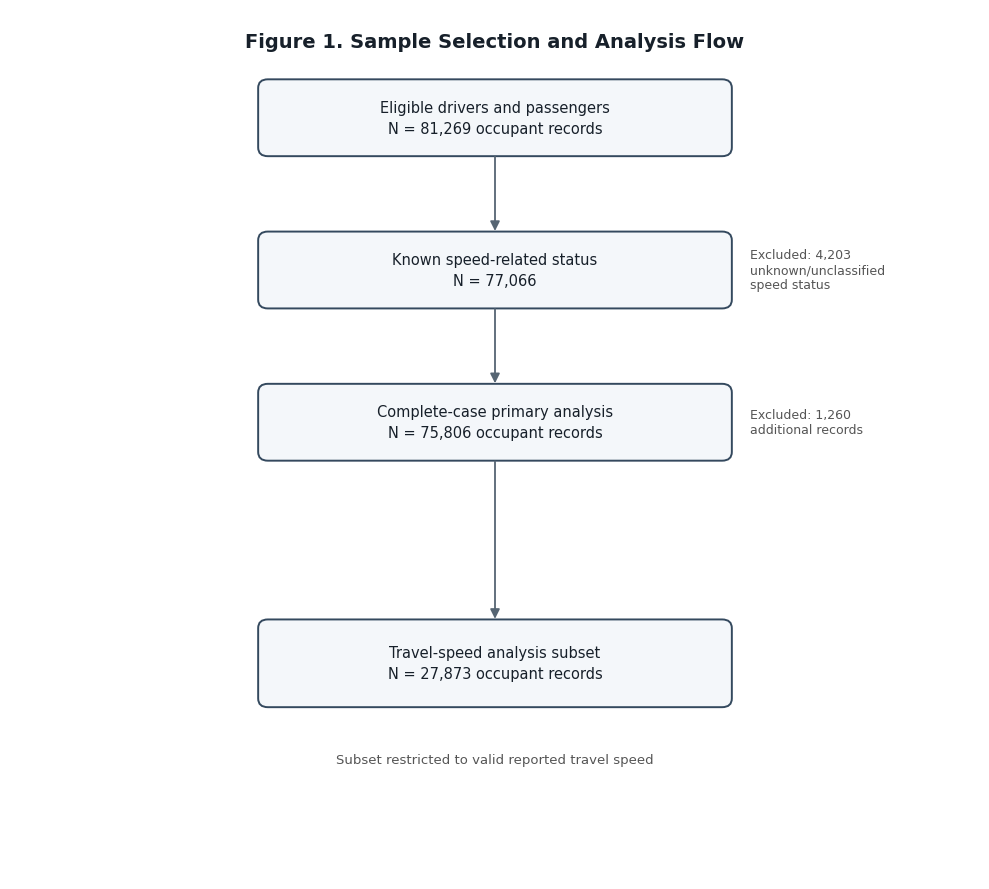

Saved files:
/content/FARS_Research_Outputs/Figure_01_Sample_Flow.png
/content/FARS_Research_Outputs/Figure_01_Sample_Flow.pdf
/content/FARS_Research_Outputs/Figure_01_Sample_Flow.svg


In [56]:

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Output folder
out_dir = "/content/FARS_Research_Outputs"
os.makedirs(out_dir, exist_ok=True)

# Publication-style figure
fig, ax = plt.subplots(figsize=(10, 9))
ax.set_xlim(0, 12)
ax.set_ylim(0, 12)
ax.axis("off")

def add_box(x, y, w, h, title, subtitle=""):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.03,rounding_size=0.12",
        linewidth=1.4,
        edgecolor="#34495E",
        facecolor="#F4F7FA"
    )
    ax.add_patch(box)

    text = title
    if subtitle:
        text += "\n" + subtitle

    ax.text(
        x + w/2, y + h/2, text,
        ha="center", va="center",
        fontsize=10.5, color="#17202A",
        linespacing=1.5
    )

def add_arrow(x1, y1, x2, y2):
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=1.3,
        color="#566573"
    )
    ax.add_patch(arrow)

# Main analysis pathway
add_box(3.1, 10.0, 5.8, 1.0,
        "Eligible drivers and passengers",
        "N = 81,269 occupant records")

add_box(3.1, 7.9, 5.8, 1.0,
        "Known speed-related status",
        "N = 77,066")

add_box(3.1, 5.8, 5.8, 1.0,
        "Complete-case primary analysis",
        "N = 75,806 occupant records")

add_arrow(6, 10.0, 6, 8.9)
add_arrow(6, 7.9, 6, 6.8)

# Exclusion annotations
ax.text(9.15, 8.4,
        "Excluded: 4,203\nunknown/unclassified\nspeed status",
        ha="left", va="center", fontsize=9, color="#555555")

ax.text(9.15, 6.3,
        "Excluded: 1,260\nadditional records",
        ha="left", va="center", fontsize=9, color="#555555")

# Separate travel-speed analysis branch
add_box(3.1, 2.4, 5.8, 1.15,
        "Travel-speed analysis subset",
        "N = 27,873 occupant records")

add_arrow(6, 5.8, 6, 3.55)

ax.text(6, 1.65,
        "Subset restricted to valid reported travel speed",
        ha="center", va="center", fontsize=9.5, color="#555555")

# Title
ax.text(
    6, 11.55,
    "Figure 1. Sample Selection and Analysis Flow",
    ha="center", va="center",
    fontsize=14, fontweight="bold", color="#17202A"
)

plt.tight_layout()

# Save in publication-friendly formats
png_path = os.path.join(out_dir, "Figure_01_Sample_Flow.png")
pdf_path = os.path.join(out_dir, "Figure_01_Sample_Flow.pdf")
svg_path = os.path.join(out_dir, "Figure_01_Sample_Flow.svg")

fig.savefig(png_path, dpi=600, bbox_inches="tight", facecolor="white")
fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
fig.savefig(svg_path, bbox_inches="tight", facecolor="white")

plt.show()
plt.close(fig)

print("Saved files:")
print(png_path)
print(pdf_path)
print(svg_path)


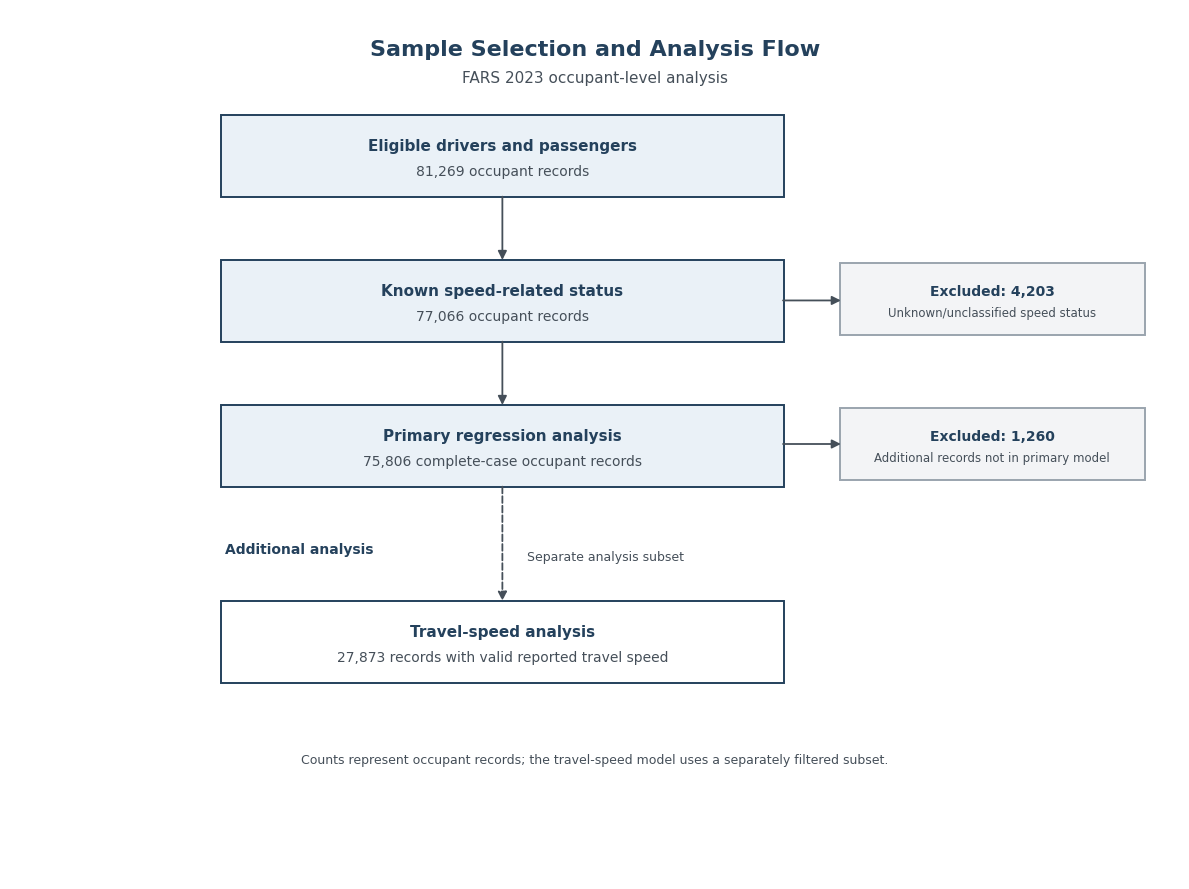

Updated sample-flow figure saved in:
/content/FARS_Research_Outputs


In [57]:

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Output directory
out_dir = "/content/FARS_Research_Outputs"
os.makedirs(out_dir, exist_ok=True)

# Clean, publication-style layout
fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xlim(0, 12)
ax.set_ylim(0, 12)
ax.axis("off")

# Neutral academic palette
navy = "#24415C"
light_blue = "#EAF1F7"
light_gray = "#F3F4F6"
dark_gray = "#454F59"
white = "#FFFFFF"

def draw_box(x, y, w, h, title, detail,
             facecolor=light_blue, edgecolor=navy,
             title_size=11, detail_size=10):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="square,pad=0.04",
        linewidth=1.4,
        edgecolor=edgecolor,
        facecolor=facecolor
    )
    ax.add_patch(box)

    ax.text(
        x + w/2, y + h*0.63, title,
        ha="center", va="center",
        fontsize=title_size, fontweight="bold",
        color=navy, wrap=True
    )
    ax.text(
        x + w/2, y + h*0.30, detail,
        ha="center", va="center",
        fontsize=detail_size, color=dark_gray,
        wrap=True
    )

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=13,
        linewidth=1.3,
        color=dark_gray,
        connectionstyle="arc3,rad=0"
    ))

# Figure heading
ax.text(
    6, 11.45,
    "Sample Selection and Analysis Flow",
    ha="center", va="center",
    fontsize=16, fontweight="bold", color=navy
)
ax.text(
    6, 11.05,
    "FARS 2023 occupant-level analysis",
    ha="center", va="center",
    fontsize=11, color=dark_gray
)

# Main vertical pathway
main_x, main_w, main_h = 2.2, 5.7, 1.05

draw_box(
    main_x, 9.45, main_w, main_h,
    "Eligible drivers and passengers",
    "81,269 occupant records"
)

draw_box(
    main_x, 7.45, main_w, main_h,
    "Known speed-related status",
    "77,066 occupant records"
)

draw_box(
    main_x, 5.45, main_w, main_h,
    "Primary regression analysis",
    "75,806 complete-case occupant records"
)

arrow(5.05, 9.45, 5.05, 8.50)
arrow(5.05, 7.45, 5.05, 6.50)

# Exclusion boxes on the right
draw_box(
    8.55, 7.55, 3.05, 0.90,
    "Excluded: 4,203",
    "Unknown/unclassified speed status",
    facecolor=light_gray,
    edgecolor="#9AA4AE",
    title_size=10,
    detail_size=8.5
)
arrow(7.9, 7.98, 8.55, 7.98)

draw_box(
    8.55, 5.55, 3.05, 0.90,
    "Excluded: 1,260",
    "Additional records not in primary model",
    facecolor=light_gray,
    edgecolor="#9AA4AE",
    title_size=10,
    detail_size=8.5
)
arrow(7.9, 6.00, 8.55, 6.00)

# Separate analysis branch
ax.text(
    2.2, 4.55,
    "Additional analysis",
    fontsize=10, fontweight="bold", color=navy,
    ha="left", va="center"
)

draw_box(
    2.2, 2.75, 5.7, 1.05,
    "Travel-speed analysis",
    "27,873 records with valid reported travel speed",
    facecolor=white,
    edgecolor=navy
)

# Dashed connector indicates a subset for a separate analysis
ax.add_patch(FancyArrowPatch(
    (5.05, 5.45), (5.05, 3.80),
    arrowstyle="-|>",
    mutation_scale=13,
    linewidth=1.3,
    linestyle="--",
    color=dark_gray
))

ax.text(
    5.3, 4.45,
    "Separate analysis subset",
    fontsize=9, color=dark_gray,
    ha="left", va="center"
)

# Footer note
ax.text(
    6, 1.65,
    "Counts represent occupant records; the travel-speed model uses a separately filtered subset.",
    ha="center", va="center",
    fontsize=9, color=dark_gray, wrap=True
)

plt.tight_layout()

# Export high-resolution and vector versions
fig.savefig(
    os.path.join(out_dir, "Figure_01_Sample_Flow.png"),
    dpi=600, bbox_inches="tight", facecolor="white"
)
fig.savefig(
    os.path.join(out_dir, "Figure_01_Sample_Flow.pdf"),
    bbox_inches="tight", facecolor="white"
)
fig.savefig(
    os.path.join(out_dir, "Figure_01_Sample_Flow.svg"),
    bbox_inches="tight", facecolor="white"
)

plt.show()
plt.close(fig)

print("Updated sample-flow figure saved in:")
print(out_dir)


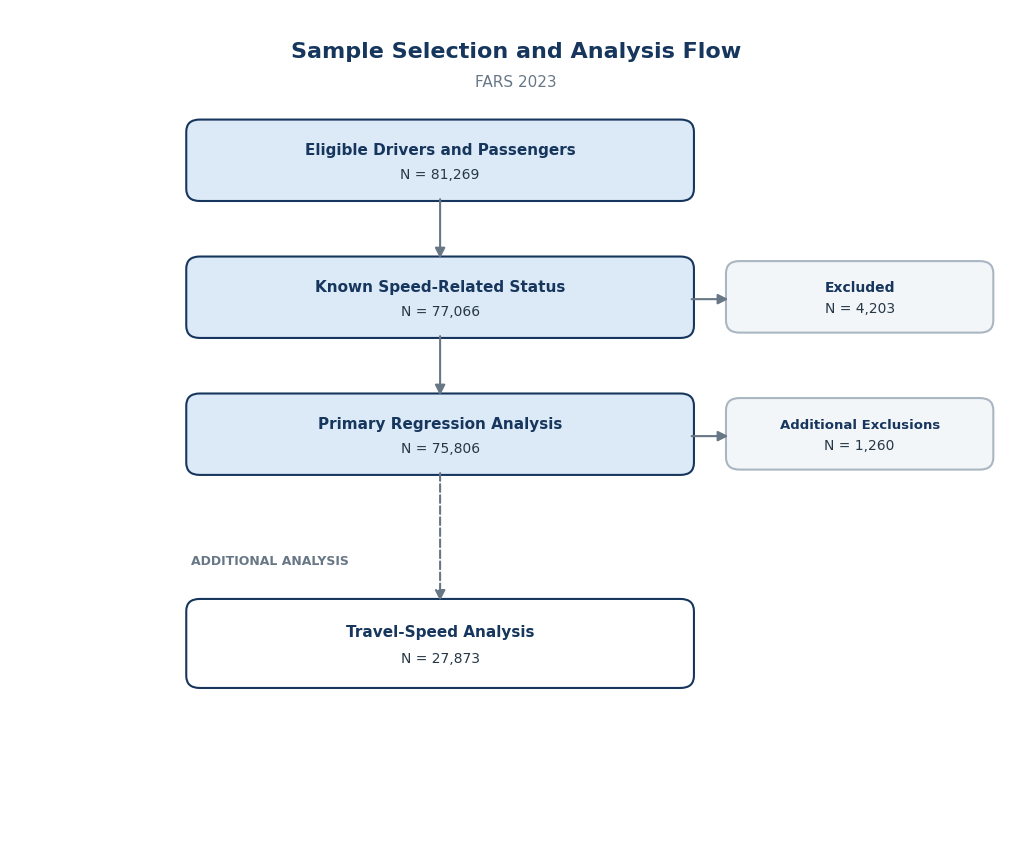

Flow diagram saved successfully.


In [58]:

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Save location
out_dir = "/content/FARS_Research_Outputs"
os.makedirs(out_dir, exist_ok=True)

# Clean academic design
fig, ax = plt.subplots(figsize=(11, 9))
fig.patch.set_facecolor("white")
ax.set_xlim(0, 12)
ax.set_ylim(0, 11)
ax.axis("off")

NAVY = "#17365D"
BLUE = "#DCEAF7"
PALE = "#F3F6F9"
GRAY = "#687786"
WHITE = "#FFFFFF"

def box(x, y, w, h, heading, value,
        face=BLUE, edge=NAVY, heading_size=11, value_size=10):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.06,rounding_size=0.16",
        linewidth=1.5,
        edgecolor=edge,
        facecolor=face
    )
    ax.add_patch(patch)

    ax.text(
        x + w/2, y + h*0.64, heading,
        ha="center", va="center",
        fontsize=heading_size, fontweight="bold",
        color=NAVY, wrap=True
    )
    ax.text(
        x + w/2, y + h*0.30, value,
        ha="center", va="center",
        fontsize=value_size, color="#263746", wrap=True
    )

def arrow(x1, y1, x2, y2, style="-"):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=15,
        linewidth=1.5,
        linestyle=style,
        color=GRAY,
        shrinkA=2, shrinkB=2
    ))

# Main title
ax.text(
    6, 10.45,
    "Sample Selection and Analysis Flow",
    ha="center", va="center",
    fontsize=16, fontweight="bold", color=NAVY
)
ax.text(
    6, 10.05,
    "FARS 2023",
    ha="center", va="center",
    fontsize=11, color=GRAY
)

# Main pathway
main_x = 2.15
main_w = 5.9
main_h = 0.95

box(main_x, 8.55, main_w, main_h,
    "Eligible Drivers and Passengers",
    "N = 81,269")

box(main_x, 6.75, main_w, main_h,
    "Known Speed-Related Status",
    "N = 77,066")

box(main_x, 4.95, main_w, main_h,
    "Primary Regression Analysis",
    "N = 75,806")

arrow(5.1, 8.55, 5.1, 7.70)
arrow(5.1, 6.75, 5.1, 5.90)

# Exclusion boxes on the right
box(8.55, 6.82, 3.05, 0.82,
    "Excluded",
    "N = 4,203",
    face=PALE, edge="#AAB6C2",
    heading_size=10, value_size=10)

box(8.55, 5.02, 3.05, 0.82,
    "Additional Exclusions",
    "N = 1,260",
    face=PALE, edge="#AAB6C2",
    heading_size=9.5, value_size=10)

arrow(8.05, 7.20, 8.55, 7.20)
arrow(8.05, 5.40, 8.55, 5.40)

# Separate travel-speed analysis
ax.text(
    2.15, 3.75,
    "ADDITIONAL ANALYSIS",
    ha="left", va="center",
    fontsize=9, fontweight="bold", color=GRAY
)

box(2.15, 2.15, 5.9, 1.05,
    "Travel-Speed Analysis",
    "N = 27,873",
    face=WHITE, edge=NAVY,
    heading_size=11, value_size=10)

arrow(5.1, 4.95, 5.1, 3.20, style="--")

# No footer, no footnotes, no small text at the bottom
plt.subplots_adjust(left=0.04, right=0.96, top=0.97, bottom=0.04)

# Export
fig.savefig(
    os.path.join(out_dir, "Figure_01_Sample_Flow.png"),
    dpi=600, bbox_inches="tight", facecolor="white"
)
fig.savefig(
    os.path.join(out_dir, "Figure_01_Sample_Flow.pdf"),
    bbox_inches="tight", facecolor="white"
)
fig.savefig(
    os.path.join(out_dir, "Figure_01_Sample_Flow.svg"),
    bbox_inches="tight", facecolor="white"
)

plt.show()
plt.close(fig)

print("Flow diagram saved successfully.")


In [59]:
import os

output_dir = "/content/FARS_Research_Outputs"

for filename in sorted(os.listdir(output_dir)):
    print(filename)

Figure_01_Injury_Severity_by_Speed.png
Figure_01_Sample_Flow.pdf
Figure_01_Sample_Flow.png
Figure_01_Sample_Flow.svg
Figure_02_Adjusted_OR_Forest_Plot.png
Figure_02_Forest_Plot_Source_Data.csv
Figure_03_Model_Comparison_AIC.png
Figure_04_Grouped_Bar_Injury_Percentage.png
Figure_04_Grouped_Bar_Source_Data.csv
Table_Injury_Severity_by_Lighting_and_Speed.csv
Table_Injury_Severity_by_Speed_Status.csv
Table_Model_Comparison.csv


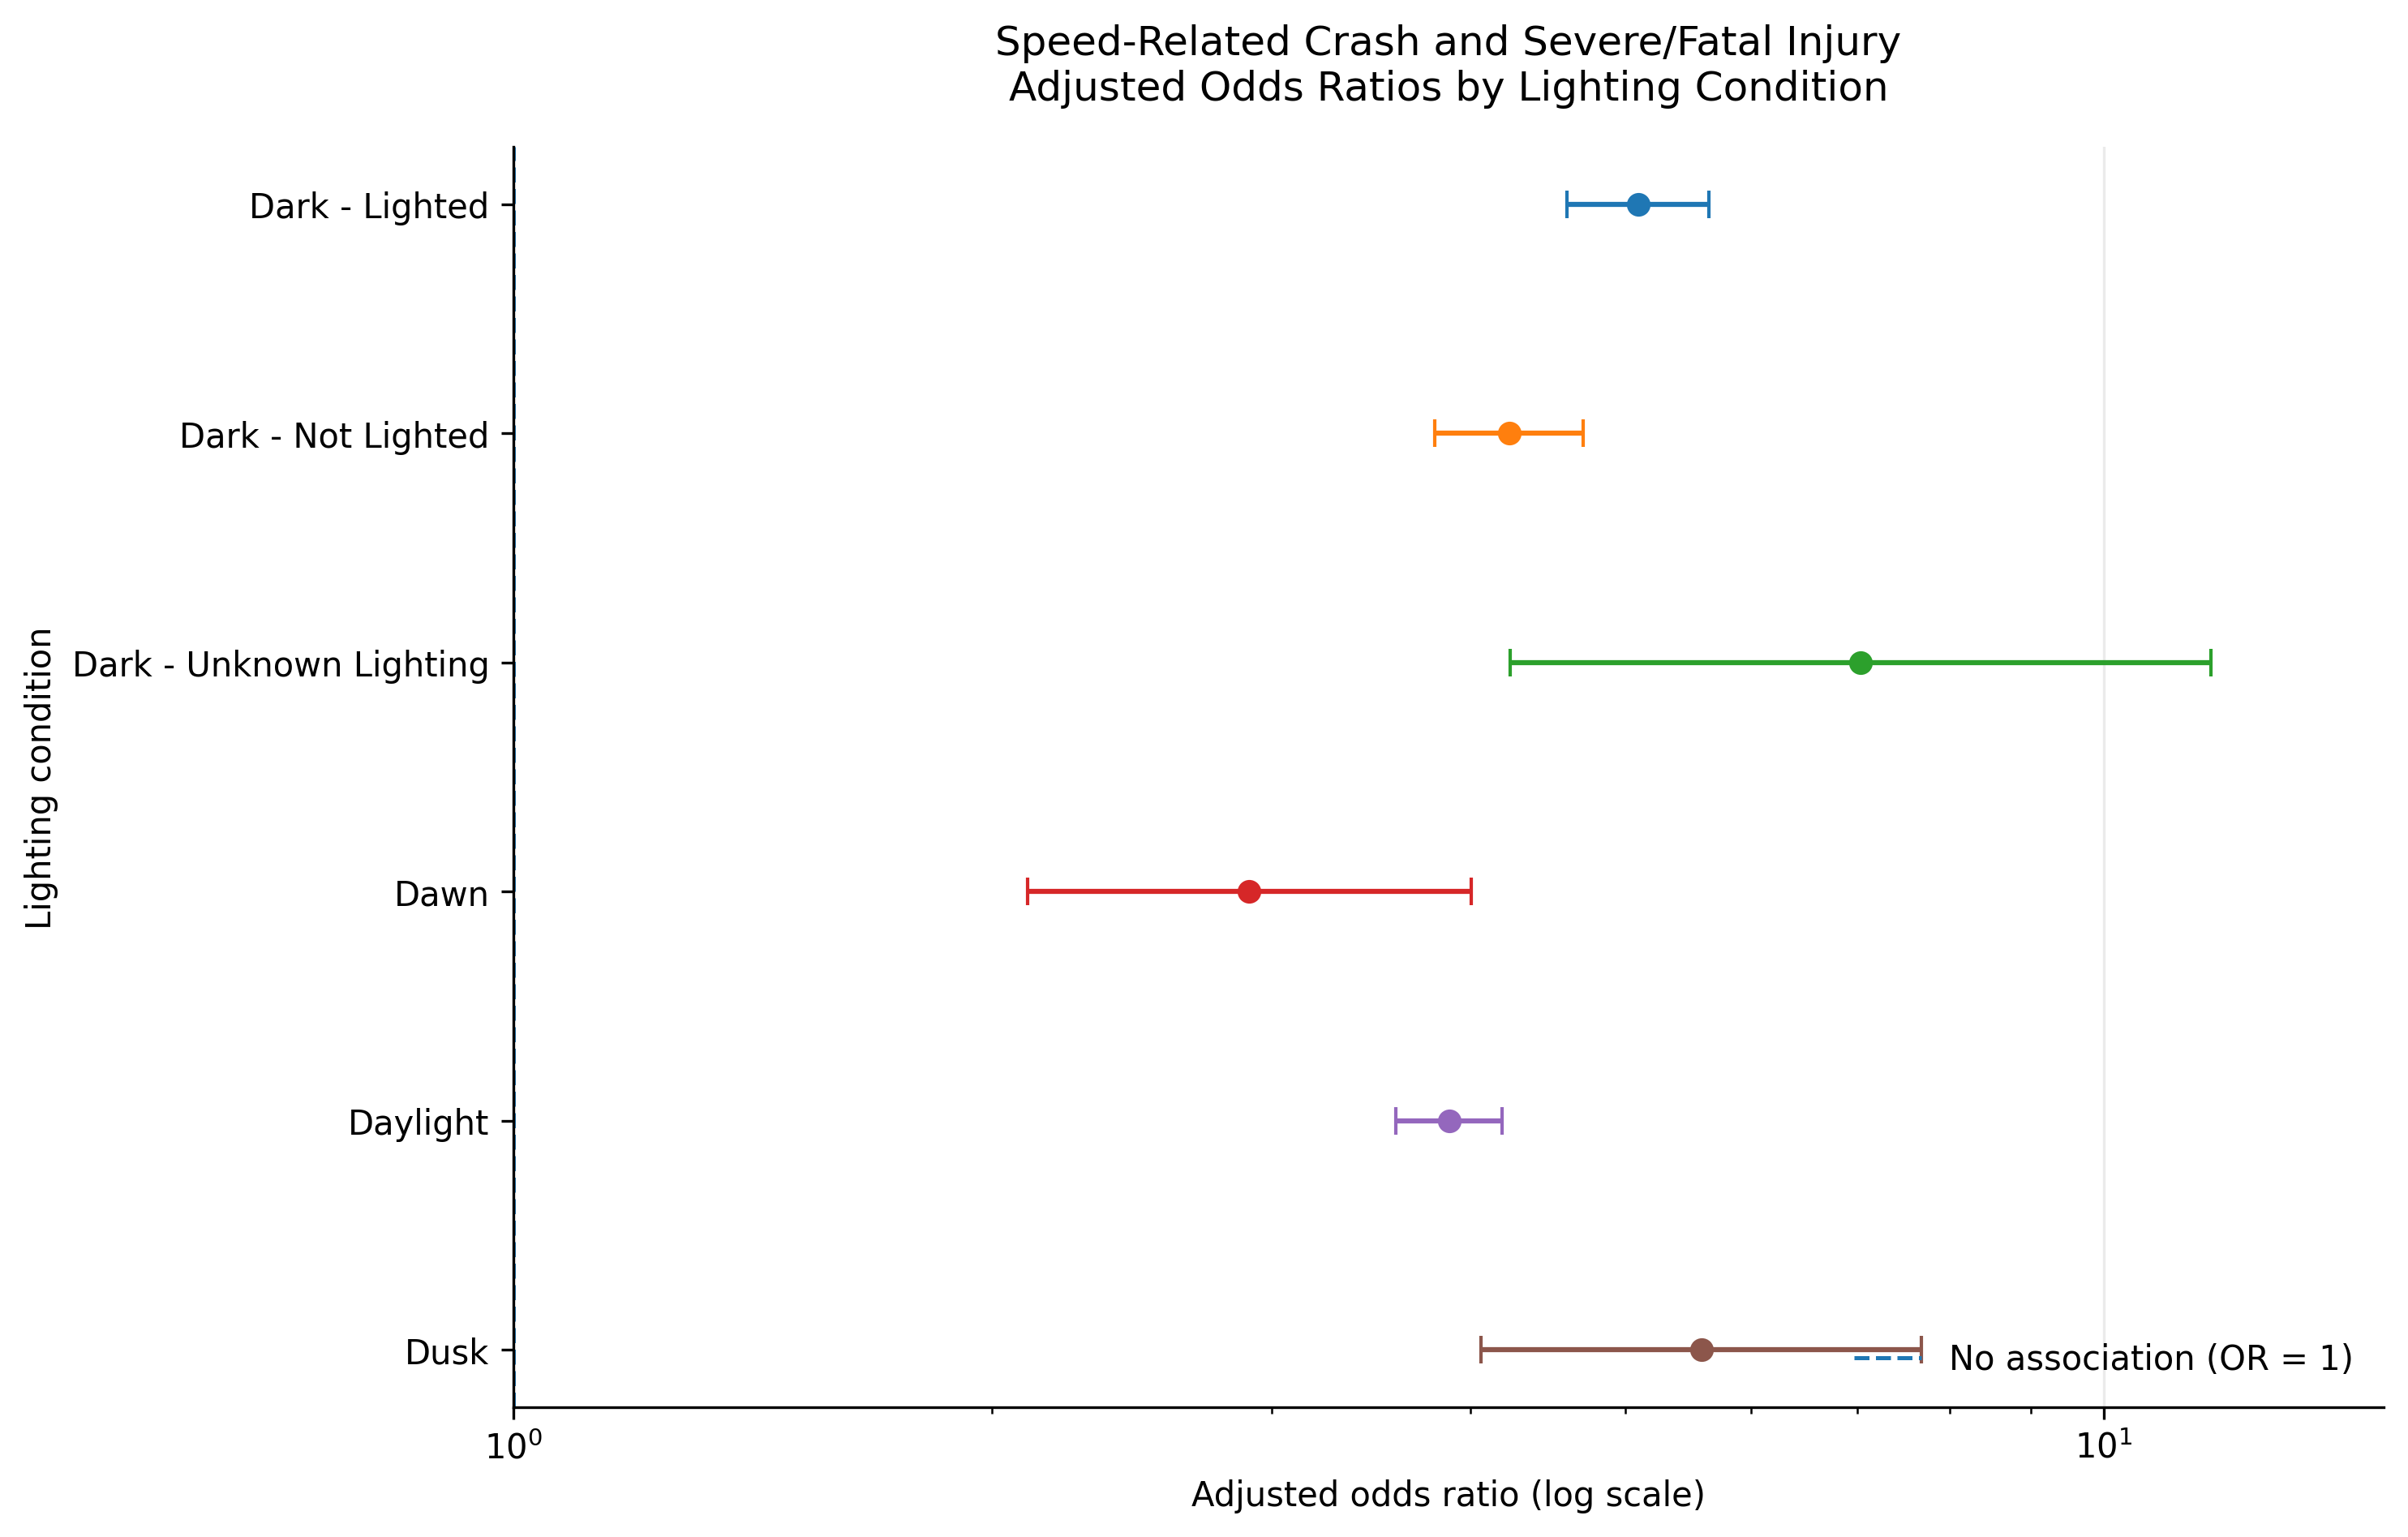

In [60]:
from IPython.display import display, Image

plot_path = (
    "/content/FARS_Research_Outputs/"
    "Figure_02_Adjusted_OR_Forest_Plot.png"
)

display(Image(filename=plot_path))

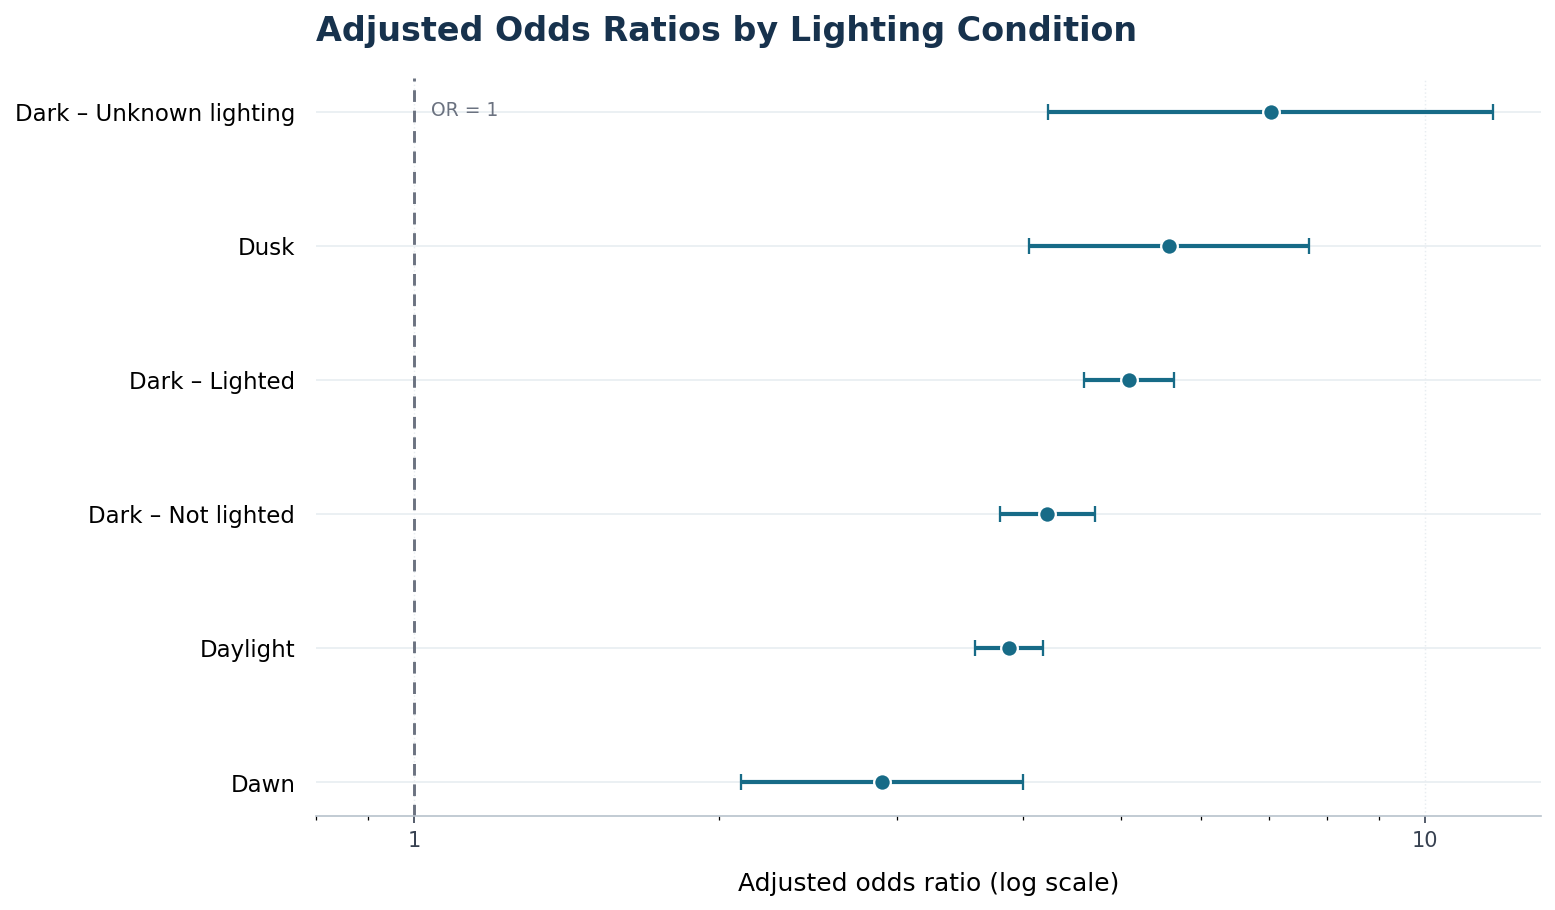

New point-and-interval plot saved successfully!
PNG: /content/FARS_Research_Outputs/Figure_02_Adjusted_OR_Point_Interval.png
PDF: /content/FARS_Research_Outputs/Figure_02_Adjusted_OR_Point_Interval.pdf
SVG: /content/FARS_Research_Outputs/Figure_02_Adjusted_OR_Point_Interval.svg


In [61]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --------------------------------------------------
# 1. File paths
# --------------------------------------------------
output_dir = "/content/FARS_Research_Outputs"
csv_path = "/content/FARS_Primary_Lighting_ORs.csv"

os.makedirs(output_dir, exist_ok=True)

# If the CSV is inside the output folder instead,
# use that file automatically.
if not os.path.exists(csv_path):
    alternative_path = os.path.join(
        output_dir, "FARS_Primary_Lighting_ORs.csv"
    )
    if os.path.exists(alternative_path):
        csv_path = alternative_path
    else:
        raise FileNotFoundError(
            "FARS_Primary_Lighting_ORs.csv পাওয়া যায়নি। "
            "CSV ফাইলের সঠিক path যাচাই করো।"
        )

# --------------------------------------------------
# 2. Read existing model results
# --------------------------------------------------
df = pd.read_csv(csv_path)

required_cols = [
    "Lighting",
    "Adjusted_OR",
    "CI_95_Lower",
    "CI_95_Upper"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"CSV-তে প্রয়োজনীয় column নেই: {missing_cols}")

# Use original interaction model if the CSV has multiple models
if "Model" in df.columns:
    original = df[
        df["Model"].astype(str).str.lower().eq("original interaction")
    ].copy()

    if not original.empty:
        df = original

# Convert numerical columns
for col in ["Adjusted_OR", "CI_95_Lower", "CI_95_Upper"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=required_cols).copy()

# Keep valid confidence intervals and positive ORs
df = df[
    (df["Adjusted_OR"] > 0) &
    (df["CI_95_Lower"] > 0) &
    (df["CI_95_Upper"] > 0)
].copy()

if df.empty:
    raise ValueError("বৈধ OR ও confidence interval-এর কোনো row পাওয়া যায়নি।")

# Short, consistent labels for publication
label_map = {
    "Dark - Lighted": "Dark – Lighted",
    "Dark - Not Lighted": "Dark – Not lighted",
    "Dark - Unknown Lighting": "Dark – Unknown lighting",
    "Daylight": "Daylight",
    "Dawn": "Dawn",
    "Dusk": "Dusk"
}

df["Lighting_display"] = (
    df["Lighting"].map(label_map).fillna(df["Lighting"])
)

# Sort from lower to higher adjusted OR
df = df.sort_values("Adjusted_OR").reset_index(drop=True)

# --------------------------------------------------
# 3. Create modern point-and-interval plot
# --------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "figure.dpi": 150,
    "savefig.dpi": 600
})

fig, ax = plt.subplots(figsize=(10.5, 6.2))

y = np.arange(len(df))
or_values = df["Adjusted_OR"].to_numpy()
ci_low = df["CI_95_Lower"].to_numpy()
ci_high = df["CI_95_Upper"].to_numpy()

# Horizontal confidence intervals
left_error = or_values - ci_low
right_error = ci_high - or_values

# Confidence intervals and point estimates
ax.errorbar(
    or_values,
    y,
    xerr=np.vstack([left_error, right_error]),
    fmt="o",
    markersize=8,
    markerfacecolor="#176B87",
    markeredgecolor="white",
    markeredgewidth=1.1,
    ecolor="#176B87",
    elinewidth=2.0,
    capsize=4,
    capthick=1.5,
    linestyle="none",
    zorder=3
)

# Reference line: OR = 1
ax.axvline(
    x=1,
    color="#6B7280",
    linewidth=1.4,
    linestyle=(0, (4, 3)),
    zorder=1
)

# Category labels
ax.set_yticks(y)
ax.set_yticklabels(df["Lighting_display"])

# Odds ratios are conventionally displayed on a log scale
ax.set_xscale("log")
ax.set_xlim(0.8, 13)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:g}")
)

# Subtle horizontal guides
ax.set_axisbelow(True)
ax.grid(
    axis="y",
    color="#E8EDF1",
    linewidth=0.8
)
ax.grid(
    axis="x",
    color="#E8EDF1",
    linewidth=0.7,
    linestyle=":"
)

# Titles and labels
ax.set_title(
    "Adjusted Odds Ratios by Lighting Condition",
    loc="left",
    pad=18,
    fontweight="bold",
    color="#17324D"
)

ax.set_xlabel(
    "Adjusted odds ratio (log scale)",
    labelpad=10
)

# Clean up frame
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#B8C2CC")

ax.tick_params(axis="y", length=0, pad=10)
ax.tick_params(axis="x", colors="#374151")

# Keep the reference line identifiable without adding a footer
ax.text(
    1.04, 0.97,
    "OR = 1",
    transform=ax.get_xaxis_transform(),
    ha="left",
    va="top",
    fontsize=9,
    color="#6B7280"
)

fig.tight_layout()

# --------------------------------------------------
# 4. Save high-resolution and vector versions
# --------------------------------------------------
png_path = os.path.join(
    output_dir, "Figure_02_Adjusted_OR_Point_Interval.png"
)
pdf_path = os.path.join(
    output_dir, "Figure_02_Adjusted_OR_Point_Interval.pdf"
)
svg_path = os.path.join(
    output_dir, "Figure_02_Adjusted_OR_Point_Interval.svg"
)

fig.savefig(png_path, dpi=600, bbox_inches="tight", facecolor="white")
fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
fig.savefig(svg_path, bbox_inches="tight", facecolor="white")

plt.show()
plt.close(fig)

print("New point-and-interval plot saved successfully!")
print("PNG:", png_path)
print("PDF:", pdf_path)
print("SVG:", svg_path)



In [62]:

import os
import pandas as pd

output_dir = "/content/FARS_Research_Outputs"

# Check that the existing analysis data is available
if "model_df" not in globals():
    raise NameError(
        "model_df পাওয়া যায়নি। আগের analysis notebook থেকে "
        "model_df তৈরি করা cell আবার চালাতে হবে।"
    )

required = ["SPEED_LABEL", "SEVERE_INJURY"]
missing = [c for c in required if c not in model_df.columns]

if missing:
    raise ValueError(f"model_df-তে column নেই: {missing}")

# Calculate observed injury severity by speed status
summary = (
    model_df
    .groupby("SPEED_LABEL", dropna=False)
    .agg(
        Total_Occupants=("SEVERE_INJURY", "size"),
        Severe_or_Fatal=("SEVERE_INJURY", "sum")
    )
    .reset_index()
)

summary["Nonsevere"] = (
    summary["Total_Occupants"] - summary["Severe_or_Fatal"]
)

summary["Severe_or_Fatal_Percent"] = (
    100 * summary["Severe_or_Fatal"] / summary["Total_Occupants"]
)

summary["Nonsevere_Percent"] = (
    100 * summary["Nonsevere"] / summary["Total_Occupants"]
)

summary = summary[
    [
        "SPEED_LABEL",
        "Total_Occupants",
        "Nonsevere",
        "Severe_or_Fatal",
        "Nonsevere_Percent",
        "Severe_or_Fatal_Percent"
    ]
]

print("OBSERVED INJURY SEVERITY BY SPEED STATUS")
display(summary.round(2))

# Save a separate QC file; existing results are not overwritten
qc_path = os.path.join(
    output_dir,
    "QC_Injury_Severity_by_Speed_Status.csv"
)

summary.to_csv(qc_path, index=False)
print("\nQC table saved to:", qc_path)


OBSERVED INJURY SEVERITY BY SPEED STATUS


,SPEED_LABEL,Total_Occupants,Nonsevere,Severe_or_Fatal,Nonsevere_Percent,Severe_or_Fatal_Percent
0,Not speed-related,60654,33582,27072,55.37,44.63
1,Speed-related,15152,3863,11289,25.49,74.51



QC table saved to: /content/FARS_Research_Outputs/QC_Injury_Severity_by_Speed_Status.csv


In [63]:

import os
import pandas as pd

output_dir = "/content/FARS_Research_Outputs"

# Use the existing analysis dataset
required = ["LIGHTING_MODEL", "SPEED_LABEL", "SEVERE_INJURY"]
missing = [c for c in required if c not in model_df.columns]

if missing:
    raise ValueError(f"Required columns missing: {missing}")

# Summarize observed injury severity by lighting and speed status
lighting_summary = (
    model_df
    .groupby(["LIGHTING_MODEL", "SPEED_LABEL"], dropna=False)
    .agg(
        Total_Occupants=("SEVERE_INJURY", "size"),
        Severe_or_Fatal=("SEVERE_INJURY", "sum")
    )
    .reset_index()
)

lighting_summary["Nonsevere"] = (
    lighting_summary["Total_Occupants"]
    - lighting_summary["Severe_or_Fatal"]
)

lighting_summary["Severe_or_Fatal_Percent"] = (
    100 * lighting_summary["Severe_or_Fatal"]
    / lighting_summary["Total_Occupants"]
)

lighting_summary["Nonsevere_Percent"] = (
    100 * lighting_summary["Nonsevere"]
    / lighting_summary["Total_Occupants"]
)

lighting_summary = lighting_summary[
    [
        "LIGHTING_MODEL",
        "SPEED_LABEL",
        "Total_Occupants",
        "Nonsevere",
        "Severe_or_Fatal",
        "Nonsevere_Percent",
        "Severe_or_Fatal_Percent"
    ]
].sort_values(["LIGHTING_MODEL", "SPEED_LABEL"])

display(lighting_summary.round(2))

# Save as a separate QC output
qc_path = os.path.join(
    output_dir,
    "QC_Injury_Severity_by_Lighting_and_Speed.csv"
)

lighting_summary.to_csv(qc_path, index=False)
print("QC table saved:", qc_path)


,LIGHTING_MODEL,SPEED_LABEL,Total_Occupants,Nonsevere,Severe_or_Fatal,Nonsevere_Percent,Severe_or_Fatal_Percent
0,Dark - Lighted,Not speed-related,11604,7400,4204,63.77,36.23
1,Dark - Lighted,Speed-related,3649,1034,2615,28.34,71.66
2,Dark - Not Lighted,Not speed-related,14620,8015,6605,54.82,45.18
3,Dark - Not Lighted,Speed-related,4164,1019,3145,24.47,75.53
4,Dark - Unknown Lighting,Not speed-related,506,317,189,62.65,37.35
5,Dark - Unknown Lighting,Speed-related,166,36,130,21.69,78.31
6,Dawn,Not speed-related,1027,509,518,49.56,50.44
7,Dawn,Speed-related,297,82,215,27.61,72.39
8,Daylight,Not speed-related,31228,16395,14833,52.50,47.50
9,Daylight,Speed-related,6466,1608,4858,24.87,75.13


QC table saved: /content/FARS_Research_Outputs/QC_Injury_Severity_by_Lighting_and_Speed.csv


In [64]:

import os
import pandas as pd

out = "/content/FARS_Research_Outputs"

qc_path = os.path.join(
    out, "QC_Injury_Severity_by_Lighting_and_Speed.csv"
)
fig_path = os.path.join(
    out, "Figure_04_Grouped_Bar_Source_Data.csv"
)

qc = pd.read_csv(qc_path)
fig = pd.read_csv(fig_path)

print("QC table columns:")
print(qc.columns.tolist())

print("\nFigure 04 source-data columns:")
print(fig.columns.tolist())

print("\nFigure 04 source data:")
display(fig)


QC table columns:
['LIGHTING_MODEL', 'SPEED_LABEL', 'Total_Occupants', 'Nonsevere', 'Severe_or_Fatal', 'Nonsevere_Percent', 'Severe_or_Fatal_Percent']

Figure 04 source-data columns:
['LIGHTING_MODEL', 'SPEED_LABEL', 'Total', 'Severe_Fatal', 'Severe_Fatal_Percent']

Figure 04 source data:


,LIGHTING_MODEL,SPEED_LABEL,Total,Severe_Fatal,Severe_Fatal_Percent
0,Dark - Lighted,Not speed-related,11604,4204,36.228887
1,Dark - Lighted,Speed-related,3649,2615,71.663469
2,Dark - Not Lighted,Not speed-related,14620,6605,45.177839
3,Dark - Not Lighted,Speed-related,4164,3145,75.528338
4,Dark - Unknown Lighting,Not speed-related,506,189,37.351779
5,Dark - Unknown Lighting,Speed-related,166,130,78.313253
6,Dawn,Not speed-related,1027,518,50.438169
7,Dawn,Speed-related,297,215,72.390572
8,Daylight,Not speed-related,31228,14833,47.499039
9,Daylight,Speed-related,6466,4858,75.131457


In [65]:

import os
import pandas as pd

out = "/content/FARS_Research_Outputs"

files_to_check = [
    "/content/FARS_Primary_Lighting_ORs.csv",
    "/content/FARS_Nonlinear_Age_Sensitivity_ORs.csv",
    os.path.join(out, "Figure_02_Forest_Plot_Source_Data.csv"),
]

for path in files_to_check:
    print("\n" + "=" * 70)
    print("File:", os.path.basename(path))

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        display(df)
    else:
        print("FILE NOT FOUND")



File: FARS_Primary_Lighting_ORs.csv
Rows: 6
Columns: ['Model', 'Lighting', 'Adjusted_OR', 'CI_95_Lower', 'CI_95_Upper', 'p_value']


,Model,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,p_value
0,Original interaction,Dark - Lighted,5.095026,4.599633,5.643774,1.063351e-213
1,Original interaction,Dark - Not Lighted,4.227896,3.795782,4.709201,2.075728e-151
2,Original interaction,Dark - Unknown Lighting,7.032217,4.235904,11.674505,4.634936e-14
3,Original interaction,Dawn,2.902346,2.104707,4.002272,8.083775e-11
4,Original interaction,Daylight,3.876408,3.589064,4.186757,1.558230e-260
5,Original interaction,Dusk,5.584542,4.059867,7.681806,3.978283e-26



File: FARS_Nonlinear_Age_Sensitivity_ORs.csv
Rows: 6
Columns: ['Model', 'Lighting', 'Adjusted_OR', 'CI_95_Lower', 'CI_95_Upper', 'p_value']


,Model,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,p_value
0,Nonlinear age sensitivity,Dark - Lighted,5.078726,4.584892,5.625751,7.618695e-213
1,Nonlinear age sensitivity,Dark - Not Lighted,4.207084,3.777291,4.685779,1.571349e-150
2,Nonlinear age sensitivity,Dark - Unknown Lighting,7.020537,4.226446,11.661792,5.196849e-14
3,Nonlinear age sensitivity,Dawn,2.909740,2.109442,4.013662,7.589121e-11
4,Nonlinear age sensitivity,Daylight,3.902792,3.613665,4.215052,1.881586e-263
5,Nonlinear age sensitivity,Dusk,5.609885,4.079056,7.715219,2.764512e-26



File: Figure_02_Forest_Plot_Source_Data.csv
Rows: 6
Columns: ['Model', 'Lighting', 'Adjusted_OR', 'CI_95_Lower', 'CI_95_Upper', 'p_value']


,Model,Lighting,Adjusted_OR,CI_95_Lower,CI_95_Upper,p_value
0,Original interaction,Dark - Lighted,5.095026,4.599633,5.643774,1.063351e-213
1,Original interaction,Dark - Not Lighted,4.227896,3.795782,4.709201,2.075728e-151
2,Original interaction,Dark - Unknown Lighting,7.032217,4.235904,11.674505,4.634936e-14
3,Original interaction,Dawn,2.902346,2.104707,4.002272,8.083775e-11
4,Original interaction,Daylight,3.876408,3.589064,4.186757,1.558230e-260
5,Original interaction,Dusk,5.584542,4.059867,7.681806,3.978283e-26


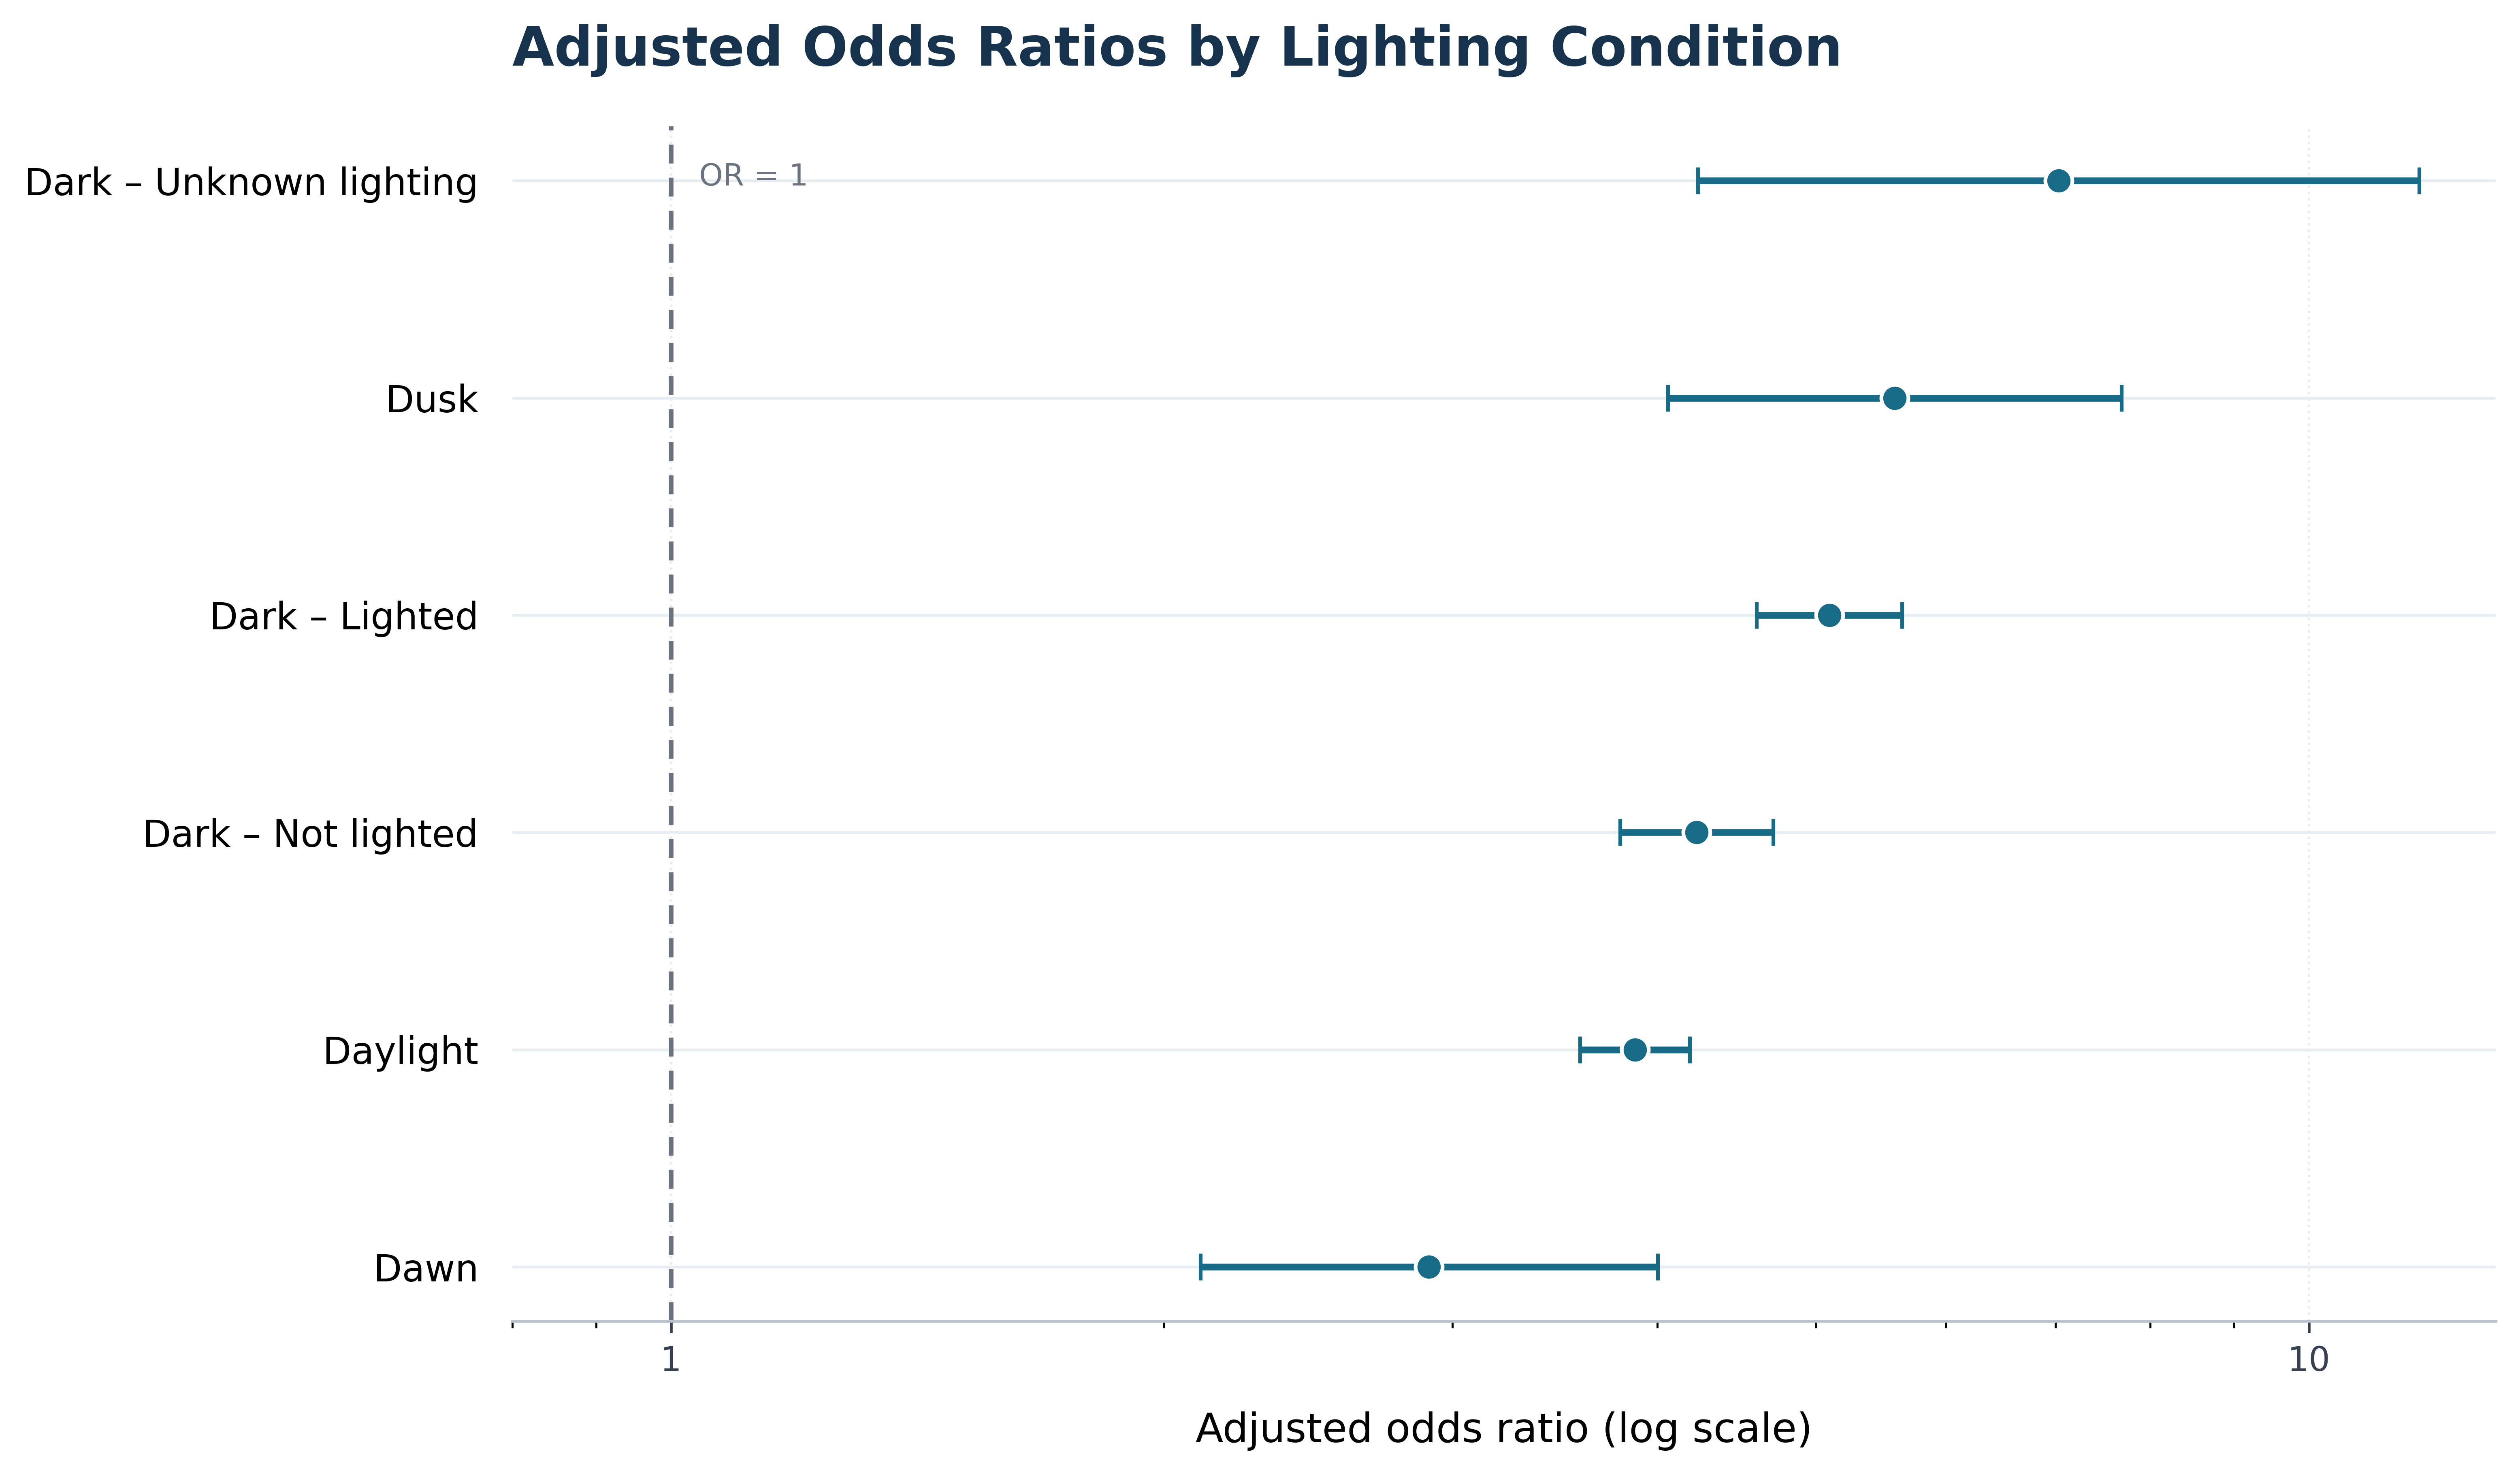

In [66]:

from IPython.display import display, Image
import os

out = "/content/FARS_Research_Outputs"
plot_path = os.path.join(
    out, "Figure_02_Adjusted_OR_Point_Interval.png"
)

if os.path.exists(plot_path):
    display(Image(filename=plot_path))
else:
    print("Figure not found:", plot_path)
    print("Available Figure 02 files:")
    for f in os.listdir(out):
        if "Figure_02" in f:
            print(f)


In [67]:

import os

out = "/content/FARS_Research_Outputs"

print("FILES IN FARS_Research_Outputs\n")

for name in sorted(os.listdir(out)):
    path = os.path.join(out, name)
    if os.path.isfile(path):
        print(f"{name}  ({os.path.getsize(path):,} bytes)")


FILES IN FARS_Research_Outputs

Figure_01_Injury_Severity_by_Speed.png  (106,371 bytes)
Figure_01_Sample_Flow.pdf  (21,247 bytes)
Figure_01_Sample_Flow.png  (465,072 bytes)
Figure_01_Sample_Flow.svg  (48,154 bytes)
Figure_02_Adjusted_OR_Forest_Plot.png  (145,399 bytes)
Figure_02_Adjusted_OR_Point_Interval.pdf  (20,862 bytes)
Figure_02_Adjusted_OR_Point_Interval.png  (296,759 bytes)
Figure_02_Adjusted_OR_Point_Interval.svg  (43,247 bytes)
Figure_02_Forest_Plot_Source_Data.csv  (726 bytes)
Figure_03_Model_Comparison_AIC.png  (144,175 bytes)
Figure_04_Grouped_Bar_Injury_Percentage.png  (212,557 bytes)
Figure_04_Grouped_Bar_Source_Data.csv  (742 bytes)
QC_Injury_Severity_by_Lighting_and_Speed.csv  (1,056 bytes)
QC_Injury_Severity_by_Speed_Status.csv  (236 bytes)
Table_Injury_Severity_by_Lighting_and_Speed.csv  (674 bytes)
Table_Injury_Severity_by_Speed_Status.csv  (186 bytes)
Table_Model_Comparison.csv  (215 bytes)


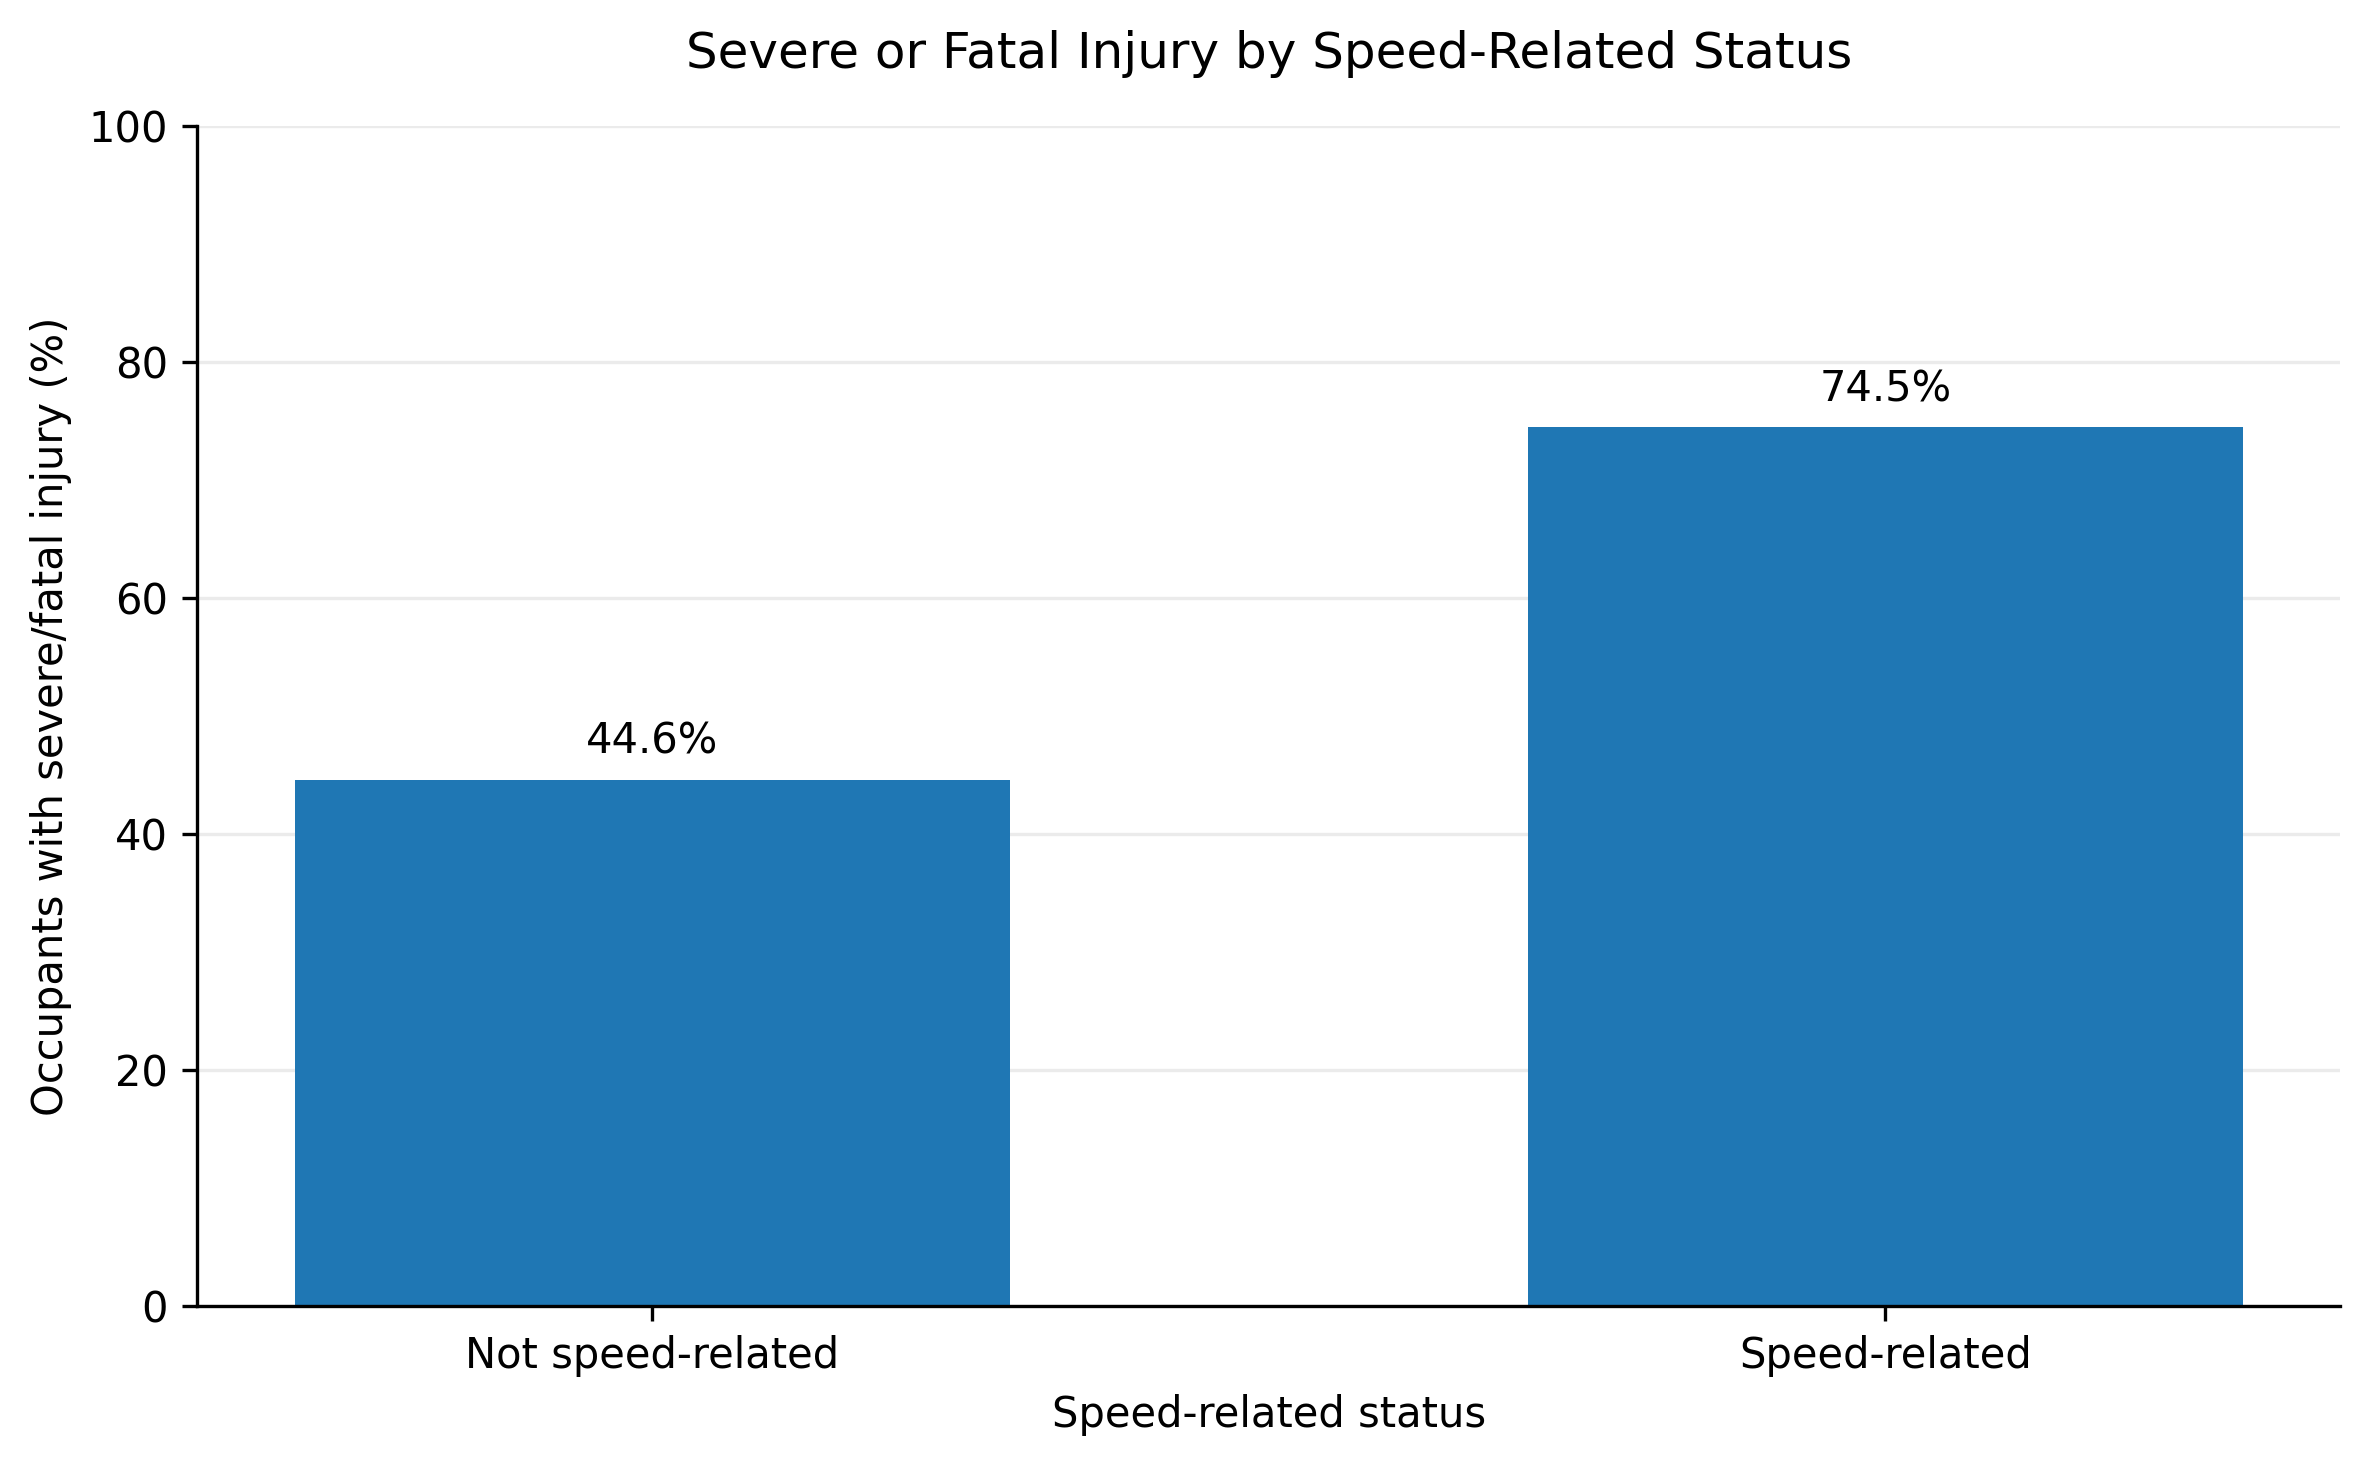

In [68]:

from IPython.display import display, Image
import os

path = "/content/FARS_Research_Outputs/Figure_01_Injury_Severity_by_Speed.png"

if os.path.exists(path):
    display(Image(filename=path))
else:
    print("Figure not found.")


In [69]:

import pandas as pd

path = "/content/FARS_Research_Outputs/Table_Model_Comparison.csv"

df = pd.read_csv(path)

display(df)


,Model,N,AIC,BIC,Pseudo_R2,Log_Likelihood
0,Main effects,75806,98342.95,98426.07,0.0643,-49162.48
1,Interaction,75806,98308.25,98437.56,0.0647,-49140.13
2,Nonlinear age sensitivity,75806,98263.59,98402.13,0.0651,-49116.79


In [70]:

import os
import pandas as pd

path = "/content/FARS_Research_Outputs"

for filename in [
    "Table_Injury_Severity_by_Speed_Status.csv",
    "Table_Injury_Severity_by_Lighting_and_Speed.csv",
]:
    file_path = os.path.join(path, filename)
    print("\n", filename)
    display(pd.read_csv(file_path))



 Table_Injury_Severity_by_Speed_Status.csv


,SPEED_LABEL,Total_occupants,Non_severe,Non_severe_percent,Severe_or_fatal,Severe_fatal_percent
0,Not speed-related,60654,33582,55.37,27072,44.63
1,Speed-related,15152,3863,25.49,11289,74.51



 Table_Injury_Severity_by_Lighting_and_Speed.csv


,LIGHTING_MODEL,SPEED_LABEL,Total_occupants,Severe_or_fatal,Severe_fatal_percent,Non_severe
0,Dark - Lighted,Not speed-related,11604,4204,36.23,7400
1,Dark - Lighted,Speed-related,3649,2615,71.66,1034
2,Dark - Not Lighted,Not speed-related,14620,6605,45.18,8015
3,Dark - Not Lighted,Speed-related,4164,3145,75.53,1019
4,Dark - Unknown Lighting,Not speed-related,506,189,37.35,317
5,Dark - Unknown Lighting,Speed-related,166,130,78.31,36
6,Dawn,Not speed-related,1027,518,50.44,509
7,Dawn,Speed-related,297,215,72.39,82
8,Daylight,Not speed-related,31228,14833,47.50,16395
9,Daylight,Speed-related,6466,4858,75.13,1608


In [71]:

import os

out = "/content/FARS_Research_Outputs"

print("Sample-flow files:")
for name in sorted(os.listdir(out)):
    if "Sample_Flow" in name:
        print(name)

print("\nOther sample-flow CSVs in /content:")
for name in sorted(os.listdir("/content")):
    if "Sample_Flow" in name and name.endswith(".csv"):
        print(name)


Sample-flow files:
Figure_01_Sample_Flow.pdf
Figure_01_Sample_Flow.png
Figure_01_Sample_Flow.svg

Other sample-flow CSVs in /content:
FARS_Final_Sample_Flow.csv


In [72]:

import pandas as pd

path = "/content/FARS_Final_Sample_Flow.csv"

df = pd.read_csv(path)

print("Columns:", df.columns.tolist())
print("Number of rows:", len(df))
display(df)


Columns: ['Stage', 'Occupant_records']
Number of rows: 4


,Stage,Occupant_records
0,Eligible drivers and passengers,81269
1,Known speed-related status,77066
2,Complete-case primary model,75806
3,Valid reported travel-speed model,27873
